**## Notebook 05: Experiments and Final Evaluation**

### COS801 Deep Learning Project

**Tittle of the Project:**Deep Learning on Tabular Data for Fraud Detection under Extreme Class Imbalance.

**## 5.1 Introduction**

This notebook is designed to compare the results of LightGBM, TabNet, and FT-Transformer on the IEEE-CIS Fraud Detection data set. The goal is to determine if a trained gradient boosted model will be better than a trained deep learning model at identifying fraudulent transactions.

The studies will assess the performance of the model, the ability to deal with imbalances in the classes being studied, the level of precision of a fixed number of alerts, the expected costs associated with false alerts, and whether the model produces reliable probabilities. The models will also be evaluated using data from future transactions in order to determine if there is a change in the model’s performance over time.

The analysis will be based on the same chronological data split and pre-processing methods that were used in the prior notebook to allow for an equitable comparison.





In [1]:
# Section 5.2: Install the required libraries.

%pip install -q kagglehub lightgbm pytorch-tabnet rtdl-revisiting-models scikit-learn pandas numpy matplotlib seaborn joblib


In [2]:
# Section 5.3: Importing the the required libraries

import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import lightgbm as lgb
import joblib
import kagglehub

from pytorch_tabnet.tab_model import TabNetClassifier
from rtdl_revisiting_models import FTTransformer

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss,
    precision_recall_curve
)

# Set the random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# Check the GPU availability
device = "cuda" if torch.cuda.is_available() else "cpu"

print("NOTEBOOK 05 - LIBRARY IMPORT CHECK")
print("-" * 45)
print("All required libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
print("Device:", device)

NOTEBOOK 05 - LIBRARY IMPORT CHECK
---------------------------------------------
All required libraries imported successfully!
PyTorch version: 2.14.1+cu130
GPU available: True
Device: cuda


### 5.4 Loading of the saved Model Results

In [3]:
# Section 5.4: Upload the saved validation results

from google.colab import files
import json

print("Please select the three validation results JSON files.")

uploaded = files.upload()

required_files = [
    "lightgbm_baseline_results.json",
    "tabnet_validation_results.json",
    "ft_transformer_validation_results.json"
]

for filename in required_files:
    if filename not in uploaded:
        raise FileNotFoundError(
            f"Missing file: {filename}. Please upload all three JSON files."
        )

results = {}

for filename in required_files:
    with open(filename, "r") as f:
        results[filename] = json.load(f)

print("\nMODEL RESULTS LOADED SUCCESSFULLY")
print("-" * 45)

for filename, data in results.items():
    print(f"\n{filename}")
    print("Available fields:", list(data.keys()))

Please select the three validation results JSON files.


Saving ft_transformer_validation_results.json to ft_transformer_validation_results.json
Saving tabnet_validation_results.json to tabnet_validation_results.json
Saving lightgbm_baseline_results.json to lightgbm_baseline_results.json

MODEL RESULTS LOADED SUCCESSFULLY
---------------------------------------------

lightgbm_baseline_results.json
Available fields: ['model', 'dataset', 'evaluation_split', 'random_state', 'average_precision', 'roc_auc', 'precision', 'recall', 'f1_score', 'brier_score', 'ece', 'best_parameters', 'best_iteration']

tabnet_validation_results.json
Available fields: ['model', 'dataset', 'evaluation_split', 'threshold', 'pr_auc', 'roc_auc', 'precision', 'recall', 'f1_score', 'brier_score', 'ece', 'training_time_seconds', 'false_negative_cost_zar', 'false_positive_cost_zar', 'estimated_cost_zar']

ft_transformer_validation_results.json
Available fields: ['model', 'dataset', 'evaluation_set', 'classification_threshold', 'average_precision', 'roc_auc', 'precision', '

### 5.5 Comparison of the LightGBM,TabNet and FT-Transformer

In [4]:
# Section 5.5: Compare the validation results

lightgbm_results = results["lightgbm_baseline_results.json"]
tabnet_results = results["tabnet_validation_results.json"]
ft_results = results["ft_transformer_validation_results.json"]

# Extract the same evaluation metrics for each model
comparison_data = [
    {
        "Model": "LightGBM",
        "PR-AUC": lightgbm_results["average_precision"],
        "ROC-AUC": lightgbm_results["roc_auc"],
        "Precision": lightgbm_results["precision"],
        "Recall": lightgbm_results["recall"],
        "F1-Score": lightgbm_results["f1_score"],
        "Brier Score": lightgbm_results["brier_score"],
        "ECE": lightgbm_results["ece"]
    },
    {
        "Model": "TabNet",
        "PR-AUC": tabnet_results["pr_auc"],
        "ROC-AUC": tabnet_results["roc_auc"],
        "Precision": tabnet_results["precision"],
        "Recall": tabnet_results["recall"],
        "F1-Score": tabnet_results["f1_score"],
        "Brier Score": tabnet_results["brier_score"],
        "ECE": tabnet_results["ece"]
    },
    {
        "Model": "FT-Transformer",
        "PR-AUC": ft_results["average_precision"],
        "ROC-AUC": ft_results["roc_auc"],
        "Precision": ft_results["precision"],
        "Recall": ft_results["recall"],
        "F1-Score": ft_results["f1_score"],
        "Brier Score": ft_results["brier_score"],
        "ECE": ft_results["expected_calibration_error"]
    }
]

comparison_df = pd.DataFrame(comparison_data)

print("VALIDATION PERFORMANCE COMPARISON")
print("-" * 55)

display(comparison_df.round(4))

print("\nBest model based on PR-AUC:")
best_model = comparison_df.loc[comparison_df["PR-AUC"].idxmax()]
print(best_model["Model"], "-", round(best_model["PR-AUC"], 4))

VALIDATION PERFORMANCE COMPARISON
-------------------------------------------------------


,Model,PR-AUC,ROC-AUC,Precision,Recall,F1-Score,Brier Score,ECE
0,LightGBM,0.6216,0.9300,0.8803,0.3748,0.5257,0.0197,0.0084
1,TabNet,0.4517,0.8574,0.7361,0.3090,0.4353,0.0242,0.0057
2,FT-Transformer,0.4505,0.8616,0.6827,0.3317,0.4465,0.0249,0.0100



Best model based on PR-AUC:
LightGBM - 0.6216


###**The interpretation of the Model Comparison**

The results of the validation in the process it demonstrates that the LighGBM it has the highest PR-AUC at 0, 6216, whereas the TabNet it is the second with the 0, 4517 and the FT-transformer it is the third with the 0, 4505. And therefore, the lightGBM had the highest ROC-AUC and the F1 score as well, which then indicates that the LighGBM it performs better overall on the validation data. And the FT-transformer have the higher recall than TabNet, while Deep learning algorithm it had lower PR-AUC they lose when we compare to the turned LightGBM model. And this suggests that under the specific circumstances that we used in this study then they turned gradient boosted 3 model was more successfully in the identifying of the fraudulent transaction.

### 5.6 Visualization comparison of the Performance of the Model

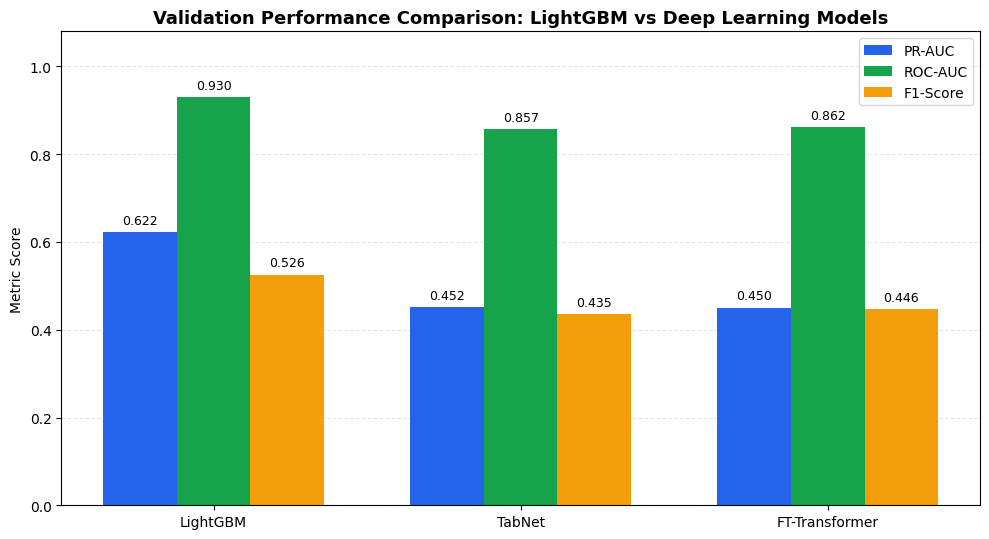

In [5]:
# Section 5.6: Visual comparison of the model performance

import matplotlib.pyplot as plt
import numpy as np

models = comparison_df["Model"]
metrics = ["PR-AUC", "ROC-AUC", "F1-Score"]

x = np.arange(len(models))
width = 0.24

fig, ax = plt.subplots(figsize=(10, 5.5))

colors = ["#2563EB", "#16A34A", "#F59E0B"]

for i, metric in enumerate(metrics):
    values = comparison_df[metric].values

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=metric,
        color=colors[i]
    )

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.012,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "Validation Performance Comparison: LightGBM vs Deep Learning Models",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Metric Score")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.08)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

###**Interpretation of figure 5.1**
Figure 5.1 it compares the validation performance of the LightGBM, TabNet and the FT-Transformer by using of the PR-AUC, ROC-AUC AND ALSO F1-score. The LightGBM has achieved the highest scores in across all the three metrics, With the PR-AUC 0.6216, ROC-AUC of the 0.9300 and the F1-score of the 0.5257. the TaNet and the FT-Transformer It produced the similar PR-AUC results of 0.4517 and zero.4505, respectively. And these findings it indicates that the LightGBM it performed better than the 2 deep learning models which is under the experimental condition used. But, further testing it is required to determine whether these results it remain consistent on the later transactions.


### 5.7 Preparing for the Class Imbalance Experiments


In [6]:
# Section 5.7: Check the required project files

required_files = [
    "lightgbm_tuned_model.joblib",
    "tabnet_trained_model.zip",
    "ft_transformer_trained_model.pth",
    "preprocessing.py"
]

print("FILES REQUIRED FOR THE NEXT EXPERIMENTS")
print("-" * 50)

for filename in required_files:
    print(filename)

FILES REQUIRED FOR THE NEXT EXPERIMENTS
--------------------------------------------------
lightgbm_tuned_model.joblib
tabnet_trained_model.zip
ft_transformer_trained_model.pth
preprocessing.py


#### 5.7.1  Uploading the Saved Models and the Preprocessing Script

In [7]:
# Section 5.7.1: Upload saved models and the preprocessing script

from google.colab import files
import os

print("Please upload the four required project files.")

uploaded_models = files.upload()

required_files = [
    "lightgbm_tuned_model.joblib",
    "tabnet_trained_model.zip",
    "ft_transformer_trained_model.pth",
    "preprocessing.py"
]

print("\nFILE UPLOAD VERIFICATION")
print("-" * 50)

all_found = True

for filename in required_files:
    if os.path.isfile(filename):
        print(f"SUCCESS: {filename}")
    else:
        print(f"MISSING: {filename}")
        all_found = False

if all_found:
    print("\nAll required files are available!")
else:
    print("\nPlease upload the missing files before continuing.")

Please upload the four required project files.


Saving tabnet_trained_model.zip to tabnet_trained_model.zip
Saving ft_transformer_trained_model.pth to ft_transformer_trained_model.pth
Saving lightgbm_tuned_model.joblib to lightgbm_tuned_model.joblib

FILE UPLOAD VERIFICATION
--------------------------------------------------
SUCCESS: lightgbm_tuned_model.joblib
SUCCESS: tabnet_trained_model.zip
SUCCESS: ft_transformer_trained_model.pth
MISSING: preprocessing.py

Please upload the missing files before continuing.


In [8]:
# Upload the preprocessing script separately
from google.colab import files

uploaded_preprocessing = files.upload()

Saving preprocessing.py to preprocessing.py


In [9]:
# Section 5.7.2: Verify all required project files

import os

required_files = [
    "lightgbm_tuned_model.joblib",
    "tabnet_trained_model.zip",
    "ft_transformer_trained_model.pth",
    "preprocessing.py"
]

print("FINAL FILE VERIFICATION")
print("-" * 45)

for filename in required_files:
    if os.path.isfile(filename):
        print("SUCCESS:", filename)
    else:
        print("MISSING:", filename)

FINAL FILE VERIFICATION
---------------------------------------------
SUCCESS: lightgbm_tuned_model.joblib
SUCCESS: tabnet_trained_model.zip
SUCCESS: ft_transformer_trained_model.pth
SUCCESS: preprocessing.py


### 5.8 Preparing of the data for Class Imbalanced Expriments

In [10]:
# Section 5.8: Inspect the preprocessing functions

import inspect
import preprocessing

functions_to_check = [
    "load_fraud_data",
    "temporal_split",
    "prepare_model_data",
    "preprocess_features",
    "run_preprocessing_pipeline"
]

print("PREPROCESSING FUNCTION SIGNATURES")
print("-" * 55)

for function_name in functions_to_check:
    if hasattr(preprocessing, function_name):
        function = getattr(preprocessing, function_name)
        print(f"{function_name}{inspect.signature(function)}")
    else:
        print(f"{function_name}: Not found")

PREPROCESSING FUNCTION SIGNATURES
-------------------------------------------------------
load_fraud_data()
temporal_split(df)
prepare_model_data(train_df, val_df, test_df)
preprocess_features(train_df, val_df, test_df)
run_preprocessing_pipeline()


#### 5.8.1 Loading and Preprocessing of the dataset

In [11]:
# Section 5.8.1: Loading  and preprocess of the the dataset

import preprocessing
import numpy as np

print("STARTING DATA PREPROCESSING")
print("-" * 50)

# Run the same preprocessing pipeline used previously
pipeline_output = preprocessing.run_preprocessing_pipeline()

print("\nPREPROCESSING PIPELINE COMPLETED")
print("-" * 50)

# Inspect the returned results before extracting the datasets
print("Returned object type:", type(pipeline_output))

if isinstance(pipeline_output, (tuple, list)):
    print("Number of returned items:", len(pipeline_output))

    for i, item in enumerate(pipeline_output):
        print(
            f"Item {i}:",
            "Type:", type(item).__name__,
            "Shape:", getattr(item, "shape", "Not applicable")
        )

elif isinstance(pipeline_output, dict):
    print("Returned keys:", list(pipeline_output.keys()))

else:
    print("Returned value:", str(pipeline_output)[:500])

STARTING DATA PREPROCESSING
--------------------------------------------------


100%|██████████| 118M/118M [00:07<00:00, 16.9MB/s]

Extracting files...


Dataset loaded successfully!
Dataset shape: (590540, 394)

TEMPORAL DATA SPLITTING
---------------------------------------------
Training set: (413378, 394)
Validation set: (88581, 394)
Testing set: (88581, 394)

Chronological order verified!

PREPROCESSING COMPLETED
---------------------------------------------
Removed features: ['dist2', 'D7']
Numerical features: 375
Categorical features: 14

MODEL DATA PREPARED
---------------------------------------------
Training features: (413378, 389)
Validation features: (88581, 389)
Testing features: (88581, 389)

PREPROCESSING PIPELINE COMPLETED
--------------------------------------------------
Returned object type: <class 'dict'>
Returned keys: ['X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test', 'time_train', 'time_val', 'time_test', 'feature_cols']


#### 5.8.2 Extracting and prepared of the Datasets

In [12]:
# Section 5.8.2: Extract the prepared datasets

X_train = pipeline_output["X_train"]
X_val = pipeline_output["X_val"]
X_test = pipeline_output["X_test"]

y_train = pipeline_output["y_train"]
y_val = pipeline_output["y_val"]
y_test = pipeline_output["y_test"]

print("DATA EXTRACTION COMPLETED")
print("-" * 50)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Testing features:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

print("\nFRAUD CLASS DISTRIBUTION")
print("-" * 50)

for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    labels_array = np.asarray(labels).ravel()

    fraud_count = int(np.sum(labels_array == 1))
    total_count = len(labels_array)
    fraud_rate = fraud_count / total_count * 100

    print(
        f"{name}: {fraud_count:,} fraud cases "
        f"out of {total_count:,} transactions "
        f"({fraud_rate:.2f}%)"
    )

DATA EXTRACTION COMPLETED
--------------------------------------------------
Training features: (413378, 389)
Validation features: (88581, 389)
Testing features: (88581, 389)

Training labels: (413378,)
Validation labels: (88581,)
Testing labels: (88581,)

FRAUD CLASS DISTRIBUTION
--------------------------------------------------
Training: 14,538 fraud cases out of 413,378 transactions (3.52%)
Validation: 3,042 fraud cases out of 88,581 transactions (3.43%)
Testing: 3,083 fraud cases out of 88,581 transactions (3.48%)


### **5.9  Class Imbalance Handling the Experiments**

### 5.9.1 Calculating the class Weights

In [13]:
# Section 5.9.1: Calculate the class weights

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Convert training labels to a NumPy array
y_train_array = np.asarray(y_train).ravel().astype(int)

# Calculate balanced class weights using training data only
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_array
)

class_weight_dict = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("CLASS WEIGHT CALCULATION")
print("-" * 50)

print("Legitimate transaction weight:",
      round(class_weight_dict[0], 4))

print("Fraud transaction weight:",
      round(class_weight_dict[1], 4))

print("\nFraud-to-legitimate weight ratio:",
      round(weights[1] / weights[0], 2))

print("\nClass weights calculated successfully!")

CLASS WEIGHT CALCULATION
--------------------------------------------------
Legitimate transaction weight: 0.5182
Fraud transaction weight: 14.2172

Fraud-to-legitimate weight ratio: 27.43

Class weights calculated successfully!


#### 5.9.2 Training the class Weighted LightGBM Model

In [14]:
# Section 5.9.2: Train the class-weighted LightGBM model

import lightgbm as lgb
import numpy as np
import time
from sklearn.metrics import average_precision_score

# Use the same training and validation datasets
y_train_array = np.asarray(y_train).ravel().astype(int)
y_val_array = np.asarray(y_val).ravel().astype(int)

# Apply class weights to the training observations
sample_weights = np.where(
    y_train_array == 1,
    class_weight_dict[1],
    class_weight_dict[0]
)

print("STARTING CLASS-WEIGHTED LIGHTGBM TRAINING")
print("-" * 55)

start_time = time.time()

# Train the weighted model
weighted_lgbm_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

weighted_lgbm_model.fit(
    X_train,
    y_train_array,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val_array)],
    eval_metric="average_precision",
    callbacks=[
        lgb.early_stopping(stopping_rounds=30, verbose=False)
    ]
)

weighted_training_time = time.time() - start_time

# Predict fraud probabilities on validation data
weighted_val_prob = weighted_lgbm_model.predict_proba(X_val)[:, 1]

# Calculate validation PR-AUC
weighted_pr_auc = average_precision_score(
    y_val_array,
    weighted_val_prob
)

print("\nCLASS-WEIGHTED LIGHTGBM TRAINING COMPLETED")
print("-" * 55)

print("Best iteration:", weighted_lgbm_model.best_iteration_)
print("Validation PR-AUC:", round(weighted_pr_auc, 4))
print("Training time (seconds):", round(weighted_training_time, 2))

STARTING CLASS-WEIGHTED LIGHTGBM TRAINING
-------------------------------------------------------

CLASS-WEIGHTED LIGHTGBM TRAINING COMPLETED
-------------------------------------------------------
Best iteration: 498
Validation PR-AUC: 0.545
Training time (seconds): 19.5


####  5.9.3 Evaluating of the Class Weighted LightGBM Model

In [15]:
# Section 5.9.3: Evaluate the class-weighted LightGBM model

import numpy as np
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)
from sklearn.calibration import calibration_curve

# Convert the probabilities into predicted classes
classification_threshold = 0.5

weighted_val_pred = (
    weighted_val_prob >= classification_threshold
).astype(int)

# Calculate the evaluation metrics
weighted_roc_auc = roc_auc_score(
    y_val_array, weighted_val_prob
)

weighted_precision = precision_score(
    y_val_array, weighted_val_pred, zero_division=0
)

weighted_recall = recall_score(
    y_val_array, weighted_val_pred, zero_division=0
)

weighted_f1 = f1_score(
    y_val_array, weighted_val_pred, zero_division=0
)

weighted_brier = brier_score_loss(
    y_val_array, weighted_val_prob
)

weighted_cm = confusion_matrix(
    y_val_array, weighted_val_pred
)

# Calculate Expected Calibration Error (ECE)
def calculate_ece(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_indices = np.digitize(
        y_prob, bin_edges[1:-1], right=True
    )

    ece = 0.0

    for bin_id in range(n_bins):
        mask = bin_indices == bin_id

        if np.any(mask):
            observed_fraud_rate = np.mean(y_true[mask])
            mean_predicted_probability = np.mean(y_prob[mask])

            ece += np.mean(mask) * abs(
                observed_fraud_rate - mean_predicted_probability
            )

    return ece

weighted_ece = calculate_ece(
    y_val_array, weighted_val_prob
)

print("CLASS-WEIGHTED LIGHTGBM VALIDATION RESULTS")
print("-" * 55)

print("PR-AUC:", round(weighted_pr_auc, 4))
print("ROC-AUC:", round(weighted_roc_auc, 4))
print("Precision:", round(weighted_precision, 4))
print("Recall:", round(weighted_recall, 4))
print("F1-score:", round(weighted_f1, 4))
print("Brier Score:", round(weighted_brier, 4))
print("Expected Calibration Error:", round(weighted_ece, 4))

print("\nCONFUSION MATRIX")
print("-" * 55)
print(weighted_cm)

CLASS-WEIGHTED LIGHTGBM VALIDATION RESULTS
-------------------------------------------------------
PR-AUC: 0.545
ROC-AUC: 0.9148
Precision: 0.2647
Recall: 0.7045
F1-score: 0.3848
Brier Score: 0.0646
Expected Calibration Error: 0.1543

CONFUSION MATRIX
-------------------------------------------------------
[[79586  5953]
 [  899  2143]]


#### 5.9.4 Saving of the Class Weighted LighGBM Model and Results

In [16]:
# Section 5.9.4: Save class-weighted LightGBM results

import os
import json
import joblib
from google.colab import files

os.makedirs("results", exist_ok=True)

# Save trained model
weighted_model_path = "results/lightgbm_class_weighted_model.joblib"
joblib.dump(weighted_lgbm_model, weighted_model_path)

# Save evaluation metrics
weighted_results = {
    "model": "Class-Weighted LightGBM",
    "evaluation_split": "validation",
    "threshold": 0.5,
    "pr_auc": float(weighted_pr_auc),
    "roc_auc": float(weighted_roc_auc),
    "precision": float(weighted_precision),
    "recall": float(weighted_recall),
    "f1_score": float(weighted_f1),
    "brier_score": float(weighted_brier),
    "ece": float(weighted_ece),
    "training_time_seconds": float(weighted_training_time),
    "best_iteration": int(weighted_lgbm_model.best_iteration_),
    "class_weights": class_weight_dict,
    "confusion_matrix": weighted_cm.tolist()
}

weighted_results_path = "results/lightgbm_class_weighted_results.json"

with open(weighted_results_path, "w") as f:
    json.dump(weighted_results, f, indent=4)

print("CLASS-WEIGHTED LIGHTGBM RESULTS SAVED")
print("-" * 50)
print("Model:", weighted_model_path)
print("Results:", weighted_results_path)

# Download files to your computer
files.download(weighted_model_path)
files.download(weighted_results_path)

CLASS-WEIGHTED LIGHTGBM RESULTS SAVED
--------------------------------------------------
Model: results/lightgbm_class_weighted_model.joblib
Results: results/lightgbm_class_weighted_results.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### 5.9.5  Random Oversampling of the Training Data

In [17]:
# Section 5.9.5: Random oversampling

import numpy as np
from sklearn.utils import resample

# Convert the training labels into a NumPy array
y_train_array = np.asarray(y_train).ravel().astype(int)

# Identify the legitimate and fraudulent transactions
normal_indices = np.where(y_train_array == 0)[0]
fraud_indices = np.where(y_train_array == 1)[0]

print("ORIGINAL TRAINING DISTRIBUTION")
print("-" * 50)
print("Legitimate transactions:", len(normal_indices))
print("Fraudulent transactions:", len(fraud_indices))

# Increase the fraud examples to 25% of legitimate examples
target_fraud_count = int(len(normal_indices) * 0.25)

oversampled_fraud_indices = resample(
    fraud_indices,
    replace=True,
    n_samples=target_fraud_count,
    random_state=42
)

# Combine the original legitimate and oversampled fraud indices
resampled_indices = np.concatenate([
    normal_indices,
    oversampled_fraud_indices
])

# Shuffle training examples
rng = np.random.default_rng(42)
rng.shuffle(resampled_indices)

# Create the oversampled training data
X_train_resampled = X_train.iloc[resampled_indices] if hasattr(
    X_train, "iloc"
) else X_train[resampled_indices]

y_train_resampled = y_train_array[resampled_indices]

print("\nOVERSAMPLED TRAINING DISTRIBUTION")
print("-" * 50)
print("Legitimate transactions:",
      np.sum(y_train_resampled == 0))
print("Fraudulent transactions:",
      np.sum(y_train_resampled == 1))
print("Total transactions:", len(y_train_resampled))

print("\nFraud percentage:",
      round(np.mean(y_train_resampled) * 100, 2), "%")

print("\nRandom oversampling completed successfully!")

ORIGINAL TRAINING DISTRIBUTION
--------------------------------------------------
Legitimate transactions: 398840
Fraudulent transactions: 14538

OVERSAMPLED TRAINING DISTRIBUTION
--------------------------------------------------
Legitimate transactions: 398840
Fraudulent transactions: 99710
Total transactions: 498550

Fraud percentage: 20.0 %

Random oversampling completed successfully!


#### 5.9.6 Training the LightGBM with the Random Oversampling

In [18]:
# Section 5.9.6: Training the  LightGBM with random oversampling

import lightgbm as lgb
import time
from sklearn.metrics import average_precision_score

print("STARTING OVERSAMPLED LIGHTGBM TRAINING")
print("-" * 55)

start_time = time.time()

# Same hyperparameters as the class-weighted experiment
oversampled_lgbm_model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

# Train on oversampled training data only
oversampled_lgbm_model.fit(
    X_train_resampled,
    y_train_resampled,
    eval_set=[(X_val, y_val_array)],
    eval_metric="average_precision",
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=30,
            verbose=False
        )
    ]
)

oversampled_training_time = time.time() - start_time

# Predict probabilities on unchanged validation data
oversampled_val_prob = oversampled_lgbm_model.predict_proba(
    X_val
)[:, 1]

# Calculate validation PR-AUC
oversampled_pr_auc = average_precision_score(
    y_val_array,
    oversampled_val_prob
)

print("\nOVERSAMPLED LIGHTGBM TRAINING COMPLETED")
print("-" * 55)

print("Best iteration:", oversampled_lgbm_model.best_iteration_)
print("Validation PR-AUC:", round(oversampled_pr_auc, 4))
print(
    "Training time (seconds):",
    round(oversampled_training_time, 2)
)

STARTING OVERSAMPLED LIGHTGBM TRAINING
-------------------------------------------------------

OVERSAMPLED LIGHTGBM TRAINING COMPLETED
-------------------------------------------------------
Best iteration: 500
Validation PR-AUC: 0.5707
Training time (seconds): 22.42


#### 5.9.7 Evaluating the Oversampled LightGBM Model

In [19]:
# Section 5.9.7: Evaluate the oversampled LightGBM model

import numpy as np
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# Use the original validation labels and predictions
y_val_array = np.asarray(y_val).ravel().astype(int)

# Classification threshold
oversampled_threshold = 0.5

# Convert predicted probabilities into classes
oversampled_val_pred = (
    oversampled_val_prob >= oversampled_threshold
).astype(int)

# Calculate evaluation metrics
oversampled_pr_auc = average_precision_score(
    y_val_array, oversampled_val_prob
)

oversampled_roc_auc = roc_auc_score(
    y_val_array, oversampled_val_prob
)

oversampled_precision = precision_score(
    y_val_array, oversampled_val_pred, zero_division=0
)

oversampled_recall = recall_score(
    y_val_array, oversampled_val_pred, zero_division=0
)

oversampled_f1 = f1_score(
    y_val_array, oversampled_val_pred, zero_division=0
)

oversampled_brier = brier_score_loss(
    y_val_array, oversampled_val_prob
)

oversampled_cm = confusion_matrix(
    y_val_array, oversampled_val_pred
)

# Use the same ECE function as Section 5.9.3
oversampled_ece = calculate_ece(
    y_val_array, oversampled_val_prob
)

print("OVERSAMPLED LIGHTGBM VALIDATION RESULTS")
print("-" * 55)

print("PR-AUC:", round(oversampled_pr_auc, 4))
print("ROC-AUC:", round(oversampled_roc_auc, 4))
print("Precision:", round(oversampled_precision, 4))
print("Recall:", round(oversampled_recall, 4))
print("F1-score:", round(oversampled_f1, 4))
print("Brier Score:", round(oversampled_brier, 4))
print("Expected Calibration Error:", round(oversampled_ece, 4))

print("\nCONFUSION MATRIX")
print("-" * 55)
print(oversampled_cm)


OVERSAMPLED LIGHTGBM VALIDATION RESULTS
-------------------------------------------------------
PR-AUC: 0.5707
ROC-AUC: 0.9207
Precision: 0.5798
Recall: 0.5076
F1-score: 0.5413
Brier Score: 0.0271
Expected Calibration Error: 0.0541

CONFUSION MATRIX
-------------------------------------------------------
[[84420  1119]
 [ 1498  1544]]


### 5.9.8 Save the Overlapsampled LightGBM Model Results

In [20]:
# Section 5.9.8: Save oversampled LightGBM results

import os
import json
from google.colab import files

os.makedirs("results", exist_ok=True)

oversampled_results = {
    "model": "LightGBM Random Oversampling",
    "evaluation_split": "validation",
    "classification_threshold": 0.5,
    "pr_auc": float(oversampled_pr_auc),
    "roc_auc": float(oversampled_roc_auc),
    "precision": float(oversampled_precision),
    "recall": float(oversampled_recall),
    "f1_score": float(oversampled_f1),
    "brier_score": float(oversampled_brier),
    "ece": float(oversampled_ece),
    "confusion_matrix": oversampled_cm.tolist()
}

results_path = "results/lightgbm_oversampled_results.json"

with open(results_path, "w") as f:
    json.dump(oversampled_results, f, indent=4)

print("OVERSAMPLED LIGHTGBM RESULTS SAVED SUCCESSFULLY")
print("File:", results_path)

files.download(results_path)


OVERSAMPLED LIGHTGBM RESULTS SAVED SUCCESSFULLY
File: results/lightgbm_oversampled_results.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 5.9.9 Save the Trainied Oversampled LightGBM Model

In [21]:
# Section 5.9.9: Save trained oversampled LightGBM model

import os
import joblib
from google.colab import files

os.makedirs("results", exist_ok=True)

# Save the already trained model
oversampled_model_path = "results/lightgbm_oversampled_model.joblib"

joblib.dump(
    oversampled_lgbm_model,
    oversampled_model_path
)

print("OVERSAMPLED LIGHTGBM MODEL SAVED SUCCESSFULLY")
print("-" * 50)
print("File:", oversampled_model_path)
print("File size:", round(
    os.path.getsize(oversampled_model_path) / (1024 * 1024), 2
), "MB")

# Download the model to your computer
files.download(oversampled_model_path)


OVERSAMPLED LIGHTGBM MODEL SAVED SUCCESSFULLY
--------------------------------------------------
File: results/lightgbm_oversampled_model.joblib
File size: 1.7 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5.10 Focal Experiment

This experiment it investigates the focal loss as then another method for handling glass imbalance in fraud detection. The focal loss reduces the contribution of the easier examples during the training, allowing the model to focus more on the difficult transactions. The model will then be trained using the original training data and evaluated on the unchanged validation dataset. Its performance and the calibration will then be compared with the standard, less weighted and the oversampled models.


### 5.10.1 The prepare for the Focal Loss Training Data


In [22]:
# Section 5.10.1: Prepare data for focal loss experiment

import numpy as np
import lightgbm as lgb

# Use the original training and validation datasets
X_train_focal = X_train
X_val_focal = X_val

y_train_focal = np.asarray(y_train).ravel().astype(int)
y_val_focal = np.asarray(y_val).ravel().astype(int)

print("FOCAL LOSS DATA PREPARATION")
print("-" * 50)

print("Training features:", X_train_focal.shape)
print("Validation features:", X_val_focal.shape)

print("Training labels:", y_train_focal.shape)
print("Validation labels:", y_val_focal.shape)

print("\nTRAINING CLASS DISTRIBUTION")
print("-" * 50)

legitimate_count = np.sum(y_train_focal == 0)
fraud_count = np.sum(y_train_focal == 1)

print("Legitimate transactions:", legitimate_count)
print("Fraudulent transactions:", fraud_count)

print(
    "Fraud percentage:",
    round(100 * fraud_count / len(y_train_focal), 2),
    "%"
)

print("\nFocal loss data prepared successfully!")


FOCAL LOSS DATA PREPARATION
--------------------------------------------------
Training features: (413378, 389)
Validation features: (88581, 389)
Training labels: (413378,)
Validation labels: (88581,)

TRAINING CLASS DISTRIBUTION
--------------------------------------------------
Legitimate transactions: 398840
Fraudulent transactions: 14538
Fraud percentage: 3.52 %

Focal loss data prepared successfully!


### 5.10.2 Define and then verify the Focal loss Objective

In [23]:
# Section 5.10.2: Define and verify focal loss

import numpy as np
from scipy.special import expit

# Focal loss parameters
focal_alpha = 0.5
focal_gamma = 2.0

def focal_loss_objective(y_true, y_pred):
    """
    Binary focal loss for LightGBM.

    y_pred contains raw prediction scores (logits).
    Returns the gradient and a positive diagonal
    Hessian approximation for stable tree training.
    """
    y_true = np.asarray(y_true, dtype=np.float64)
    logits = np.asarray(y_pred, dtype=np.float64)

    p = np.clip(expit(logits), 1e-7, 1 - 1e-7)

    # Probability assigned to the correct class
    pt = np.where(y_true == 1, p, 1 - p)

    # Class-specific focal weighting
    alpha_t = np.where(
        y_true == 1,
        focal_alpha,
        1 - focal_alpha
    )

    # Exact first derivative of focal loss
    grad = (
        alpha_t
        * (p - y_true)
        * (1 - pt) ** focal_gamma
        * (
            (1 - pt)
            - focal_gamma * pt * np.log(pt)
        )
    )

    # Positive diagonal Hessian approximation
    # (not the exact second derivative)
    hess = (
        alpha_t
        * (1 - pt) ** focal_gamma
        * p * (1 - p)
    )

    hess = np.maximum(hess, 1e-8)

    return grad, hess


# Verify the objective using sample predictions
sample_labels = np.array([0, 1, 0, 1])
sample_logits = np.array([-2.0, 2.0, 1.0, -1.0])

test_grad, test_hess = focal_loss_objective(
    sample_labels,
    sample_logits
)

print("FOCAL LOSS OBJECTIVE VERIFICATION")
print("-" * 50)

print("Alpha:", focal_alpha)
print("Gamma:", focal_gamma)
print("Gradient:", np.round(test_grad, 6))
print("Hessian approximation:", np.round(test_hess, 6))

print("\nAll gradients finite:", np.isfinite(test_grad).all())
print("All Hessians finite:", np.isfinite(test_hess).all())
print("All Hessians positive:", np.all(test_hess > 0))

assert np.isfinite(test_grad).all()
assert np.isfinite(test_hess).all()
assert np.all(test_hess > 0)

print("\nFocal loss objective verification completed!")


FOCAL LOSS OBJECTIVE VERIFICATION
--------------------------------------------------
Alpha: 0.5
Gamma: 2.0
Gradient: [ 0.00029  -0.00029   0.280812 -0.280812]
Hessian approximation: [0.000746 0.000746 0.052539 0.052539]

All gradients finite: True
All Hessians finite: True
All Hessians positive: True

Focal loss objective verification completed!


### 5.10.3 Train the LightGBM with the Focal loss.

In [24]:
# Section 5.10.3: Train LightGBM with focal loss

import lightgbm as lgb
import numpy as np
import time
from sklearn.metrics import average_precision_score
from scipy.special import expit

print("STARTING FOCAL LOSS LIGHTGBM TRAINING")
print("-" * 55)

start_time = time.time()

# Configure LightGBM using our custom focal loss
focal_lgbm_model = lgb.LGBMClassifier(
    objective=focal_loss_objective,
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1
)

# Train on the original training dataset
focal_lgbm_model.fit(
    X_train_focal,
    y_train_focal
)

focal_training_time = time.time() - start_time

# Custom objectives return raw scores.
# Convert raw scores to values between 0 and 1.
focal_val_logits = focal_lgbm_model.predict(
    X_val_focal,
    raw_score=True
)

focal_val_prob = expit(focal_val_logits)

# Calculate validation PR-AUC
focal_pr_auc = average_precision_score(
    y_val_focal,
    focal_val_prob
)

print("\nFOCAL LOSS LIGHTGBM TRAINING COMPLETED")
print("-" * 55)

print("Training iterations:", focal_lgbm_model.n_estimators)
print("Validation PR-AUC:", round(focal_pr_auc, 4))
print(
    "Training time (seconds):",
    round(focal_training_time, 2)
)


STARTING FOCAL LOSS LIGHTGBM TRAINING
-------------------------------------------------------

FOCAL LOSS LIGHTGBM TRAINING COMPLETED
-------------------------------------------------------
Training iterations: 500
Validation PR-AUC: 0.6041
Training time (seconds): 24.46


### 5.10.4 Evaluate the Fatal loss LightGBM Model

In [25]:
# Section 5.10.4: Evaluate focal loss LightGBM

import numpy as np
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    brier_score_loss
)

# Use the unchanged validation labels
y_focal_true = np.asarray(y_val_focal).ravel().astype(int)

# Classification threshold
focal_threshold = 0.5

# Convert model scores into predicted classes
focal_val_pred = (
    focal_val_prob >= focal_threshold
).astype(int)

# Calculate evaluation metrics
focal_pr_auc = average_precision_score(
    y_focal_true, focal_val_prob
)

focal_roc_auc = roc_auc_score(
    y_focal_true, focal_val_prob
)

focal_precision = precision_score(
    y_focal_true, focal_val_pred, zero_division=0
)

focal_recall = recall_score(
    y_focal_true, focal_val_pred, zero_division=0
)

focal_f1 = f1_score(
    y_focal_true, focal_val_pred, zero_division=0
)

focal_brier = brier_score_loss(
    y_focal_true, focal_val_prob
)

focal_cm = confusion_matrix(
    y_focal_true, focal_val_pred
)

# Use the ECE function defined earlier in Notebook 05
focal_ece = calculate_ece(
    y_focal_true, focal_val_prob
)

print("FOCAL LOSS LIGHTGBM VALIDATION RESULTS")
print("-" * 55)

print("PR-AUC:", round(focal_pr_auc, 4))
print("ROC-AUC:", round(focal_roc_auc, 4))
print("Precision:", round(focal_precision, 4))
print("Recall:", round(focal_recall, 4))
print("F1-score:", round(focal_f1, 4))
print("Brier Score:", round(focal_brier, 4))
print("Expected Calibration Error:", round(focal_ece, 4))

print("\nCONFUSION MATRIX")
print("-" * 55)
print(focal_cm)


FOCAL LOSS LIGHTGBM VALIDATION RESULTS
-------------------------------------------------------
PR-AUC: 0.6041
ROC-AUC: 0.9213
Precision: 0.8751
Recall: 0.3685
F1-score: 0.5186
Brier Score: 0.0452
Expected Calibration Error: 0.1544

CONFUSION MATRIX
-------------------------------------------------------
[[85379   160]
 [ 1921  1121]]


### 5.10.5 Save the Fotal Loss Evaluation Results

In [26]:
# Section 5.10.5: Save focal loss model and results

import os
import json
import joblib
from google.colab import files

os.makedirs("results", exist_ok=True)

# Save the trained model
focal_model_path = "results/lightgbm_focal_loss_model.joblib"

joblib.dump(focal_lgbm_model, focal_model_path)

# Save the validation results
focal_results = {
    "model": "LightGBM Focal Loss",
    "evaluation_split": "validation",
    "classification_threshold": float(focal_threshold),
    "focal_alpha": float(focal_alpha),
    "focal_gamma": float(focal_gamma),
    "hessian": "positive diagonal approximation",
    "training_iterations": 500,
    "training_time_seconds": float(focal_training_time),
    "pr_auc": float(focal_pr_auc),
    "roc_auc": float(focal_roc_auc),
    "precision": float(focal_precision),
    "recall": float(focal_recall),
    "f1_score": float(focal_f1),
    "brier_score": float(focal_brier),
    "ece": float(focal_ece),
    "confusion_matrix": focal_cm.tolist()
}

focal_results_path = "results/lightgbm_focal_loss_results.json"

with open(focal_results_path, "w") as f:
    json.dump(focal_results, f, indent=4)

print("FOCAL LOSS MODEL AND RESULTS SAVED SUCCESSFULLY")
print("-" * 55)

print("Model:", focal_model_path)
print("Results:", focal_results_path)

print(
    "Model size:",
    round(os.path.getsize(focal_model_path) / (1024 * 1024), 2),
    "MB"
)

# Download both files
files.download(focal_model_path)
files.download(focal_results_path)


FOCAL LOSS MODEL AND RESULTS SAVED SUCCESSFULLY
-------------------------------------------------------
Model: results/lightgbm_focal_loss_model.joblib
Results: results/lightgbm_focal_loss_results.json
Model size: 1.68 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5.11 Comparision of the Class Imbalanced Strategies

In [27]:
# Section 5.11.1: Compare class imbalance strategies

import json
import os
import pandas as pd

# Results saved from previous experiments
result_files = {
    "Original LightGBM": "lightgbm_baseline_results.json",
    "Class Weighting": "lightgbm_class_weighted_results.json",
    "Random Oversampling": "lightgbm_oversampled_results.json",
    "Focal Loss": "lightgbm_focal_loss_results.json"
}

# Load results from the current Colab session or results folder
comparison_rows = []

for method, filename in result_files.items():
    if os.path.exists(filename):
        file_path = filename
    elif os.path.exists(os.path.join("results", filename)):
        file_path = os.path.join("results", filename)
    else:
        print(f"Missing results file: {filename}")
        continue

    with open(file_path, "r") as f:
        result = json.load(f)

    def get_metric(*keys):
        for key in keys:
            if key in result and result[key] is not None:
                return float(result[key])
        return None

    comparison_rows.append({
        "Method": method,
        "PR-AUC": get_metric("pr_auc", "average_precision"),
        "ROC-AUC": get_metric("roc_auc"),
        "Precision": get_metric("precision"),
        "Recall": get_metric("recall"),
        "F1-Score": get_metric("f1_score"),
        "Brier Score": get_metric("brier_score"),
        "ECE": get_metric("ece", "expected_calibration_error")
    })

imbalance_comparison_df = pd.DataFrame(comparison_rows)

print("CLASS IMBALANCE STRATEGY COMPARISON")
print("-" * 55)

if len(imbalance_comparison_df) == 4:
    display(imbalance_comparison_df.round(4))

    best_method = imbalance_comparison_df.loc[
        imbalance_comparison_df["PR-AUC"].idxmax()
    ]

    print("\nBest method based on PR-AUC:")
    print(best_method["Method"])
    print("PR-AUC:", round(best_method["PR-AUC"], 4))
else:
    print("Expected 4 methods, found:", len(imbalance_comparison_df))
    display(imbalance_comparison_df)
    print("Upload any missing JSON files before continuing.")


CLASS IMBALANCE STRATEGY COMPARISON
-------------------------------------------------------


,Method,PR-AUC,ROC-AUC,Precision,Recall,F1-Score,Brier Score,ECE
0,Original LightGBM,0.6216,0.9300,0.8803,0.3748,0.5257,0.0197,0.0084
1,Class Weighting,0.5450,0.9148,0.2647,0.7045,0.3848,0.0646,0.1543
2,Random Oversampling,0.5707,0.9207,0.5798,0.5076,0.5413,0.0271,0.0541
3,Focal Loss,0.6041,0.9213,0.8751,0.3685,0.5186,0.0452,0.1544



Best method based on PR-AUC:
Original LightGBM
PR-AUC: 0.6216


### 5.11.2 Visualization of the Comparision and the class Imbalance Strategies

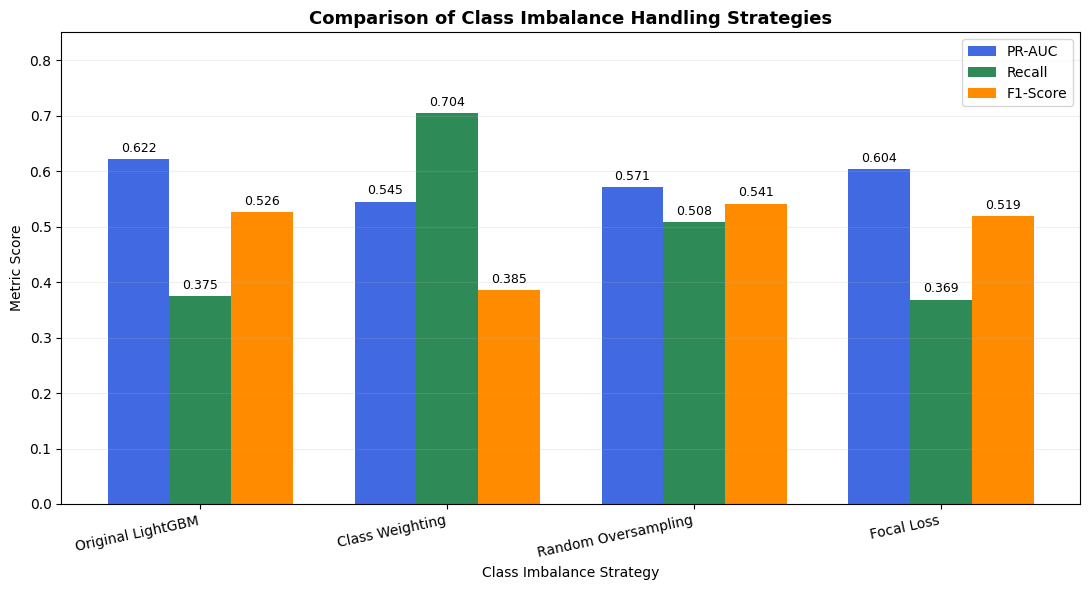

In [28]:
# Section 5.11.2: Visual comparison of imbalance strategies

import matplotlib.pyplot as plt
import numpy as np

methods = imbalance_comparison_df["Method"]
x = np.arange(len(methods))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width,
    imbalance_comparison_df["PR-AUC"],
    width,
    label="PR-AUC",
    color="royalblue"
)

bars2 = ax.bar(
    x,
    imbalance_comparison_df["Recall"],
    width,
    label="Recall",
    color="seagreen"
)

bars3 = ax.bar(
    x + width,
    imbalance_comparison_df["F1-Score"],
    width,
    label="F1-Score",
    color="darkorange"
)

for bars in [bars1, bars2, bars3]:
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_title(
    "Comparison of Class Imbalance Handling Strategies",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel("Metric Score")
ax.set_xlabel("Class Imbalance Strategy")
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=12, ha="right")
ax.set_ylim(0, 0.85)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


### 5.12 Caliberation Comparison of the class Imbalanced Strategyies.

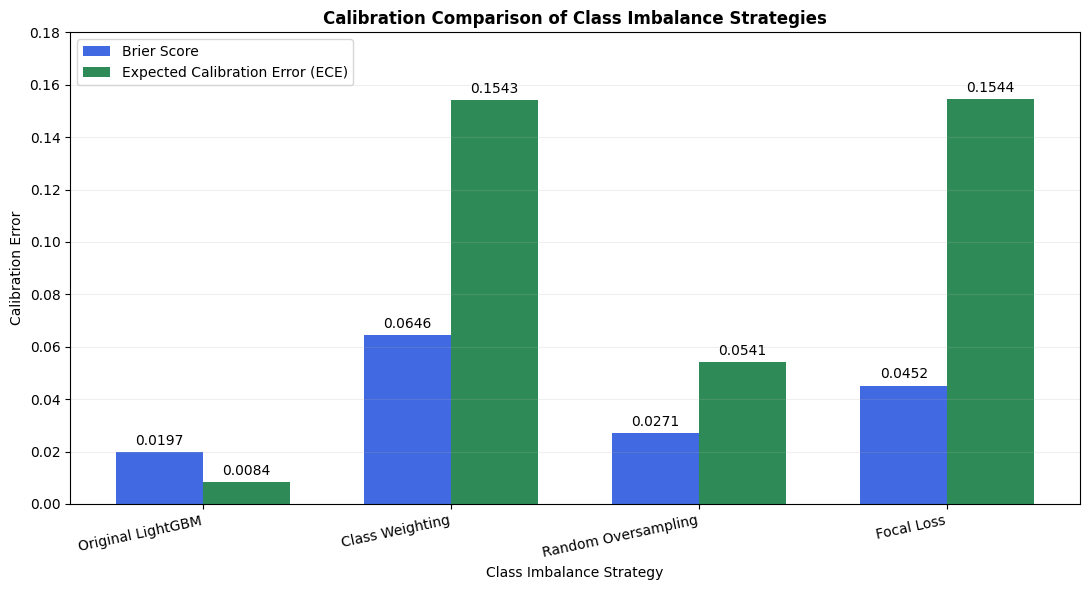

CALIBRATION COMPARISON COMPLETED
Lower Brier Score and ECE indicate better calibration.


In [29]:
# Section 5.12: Compare probability calibration

import matplotlib.pyplot as plt
import numpy as np

methods = [
    "Original LightGBM",
    "Class Weighting",
    "Random Oversampling",
    "Focal Loss"
]

brier_scores = [0.0197, 0.0646, 0.0271, 0.0452]
ece_scores = [0.0084, 0.1543, 0.0541, 0.1544]

x = np.arange(len(methods))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width/2,
    brier_scores,
    width,
    label="Brier Score",
    color="royalblue"
)

bars2 = ax.bar(
    x + width/2,
    ece_scores,
    width,
    label="Expected Calibration Error (ECE)",
    color="seagreen"
)

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

ax.set_title(
    "Calibration Comparison of Class Imbalance Strategies",
    fontweight="bold"
)

ax.set_ylabel("Calibration Error")
ax.set_xlabel("Class Imbalance Strategy")
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=12, ha="right")
ax.set_ylim(0, 0.18)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("CALIBRATION COMPARISON COMPLETED")
print("Lower Brier Score and ECE indicate better calibration.")


### 5.13 Interpretation of the Class Imbalanced experiments

### **5.13 Interpretation of the class imbalance experiments**
the experiment it compared the original light GBM model with the three glass imbalance handling methods which are weighting, random oversampling and the focal loss. The original LightGBM it has achieved the highest PR-AUC of 0, 6216 and the lowest calibration errors. The glass waiting achieved the highest recall of the zero, 7045 meaning it has identified the more from to land transactions, but it also produced the more false alarms.

And therefore, the random ovalsampling has achieved the highest F1 score of this zero, 5413 whereas the focal loss achieved a PR-AUC of 0, 6041. And in overall, the results it showed that the handling glass imbalance involves tradeoff between the detecting fraud, the reducing false alarms and the producing reliability probability estimates and there is no single strategy perform based across every matrix.


### 5.14 The Final Model Evaluation on the unseen Test Dataset

In [30]:
# Section 5.14.1: Verify test data and trained models

import os
import numpy as np

print("FINAL TEST DATA VERIFICATION")
print("-" * 50)

# Check the test dataset
required_variables = ["X_test", "y_test"]

for name in required_variables:
    if name in globals():
        value = globals()[name]
        print(f"SUCCESS: {name} available - Shape: {value.shape}")
    else:
        print(f"MISSING: {name}")

# Check saved model files
model_files = [
    "lightgbm_tuned_model.joblib",
    "lightgbm_class_weighted_model.joblib",
    "lightgbm_oversampled_model.joblib",
    "lightgbm_focal_loss_model.joblib",
    "tabnet_trained_model.zip",
    "ft_transformer_trained_model.pth"
]

print("\nTRAINED MODEL FILE VERIFICATION")
print("-" * 50)

for filename in model_files:
    possible_paths = [
        filename,
        os.path.join("results", filename)
    ]

    found_path = next(
        (path for path in possible_paths if os.path.isfile(path)),
        None
    )

    if found_path:
        print(f"SUCCESS: {filename} - {found_path}")
    else:
        print(f"MISSING: {filename}")

print("\nTEST DATA FRAUD DISTRIBUTION")
print("-" * 50)

if "y_test" in globals():
    y_test_array = np.asarray(y_test).ravel()
    print("Total test transactions:", len(y_test_array))
    print("Fraud transactions:", int(np.sum(y_test_array == 1)))
    print("Legitimate transactions:", int(np.sum(y_test_array == 0)))
    print("Fraud percentage:", round(np.mean(y_test_array == 1) * 100, 2), "%")


FINAL TEST DATA VERIFICATION
--------------------------------------------------
SUCCESS: X_test available - Shape: (88581, 389)
SUCCESS: y_test available - Shape: (88581,)

TRAINED MODEL FILE VERIFICATION
--------------------------------------------------
SUCCESS: lightgbm_tuned_model.joblib - lightgbm_tuned_model.joblib
SUCCESS: lightgbm_class_weighted_model.joblib - results/lightgbm_class_weighted_model.joblib
SUCCESS: lightgbm_oversampled_model.joblib - results/lightgbm_oversampled_model.joblib
SUCCESS: lightgbm_focal_loss_model.joblib - results/lightgbm_focal_loss_model.joblib
SUCCESS: tabnet_trained_model.zip - tabnet_trained_model.zip
SUCCESS: ft_transformer_trained_model.pth - ft_transformer_trained_model.pth

TEST DATA FRAUD DISTRIBUTION
--------------------------------------------------
Total test transactions: 88581
Fraud transactions: 3083
Legitimate transactions: 85498
Fraud percentage: 3.48 %


### 5.14.2 Loading the Train LightGBM Models


In [31]:
# Section 5.14.2: Loading saved LightGBM models

import os
import joblib

model_filenames = {
    "Original LightGBM": "lightgbm_tuned_model.joblib",
    "Class Weighting": "lightgbm_class_weighted_model.joblib",
    "Random Oversampling": "lightgbm_oversampled_model.joblib",
    "Focal Loss": "lightgbm_focal_loss_model.joblib"
}

loaded_models = {}

print("LOADING TRAINED LIGHTGBM MODELS")
print("-" * 50)

for model_name, filename in model_filenames.items():

    possible_paths = [
        filename,
        os.path.join("results", filename)
    ]

    model_path = next(
        (path for path in possible_paths if os.path.isfile(path)),
        None
    )

    if model_path is None:
        print(f"MISSING: {model_name}")
        continue

    try:
        loaded_models[model_name] = joblib.load(model_path)
        print(f"SUCCESS: {model_name}")
        print(f"File: {model_path}")

    except Exception as error:
        print(f"ERROR loading {model_name}: {error}")

print("\nMODEL LOADING SUMMARY")
print("-" * 50)
print("Successfully loaded:", len(loaded_models), "of", len(model_filenames))

if len(loaded_models) == len(model_filenames):
    print("All LightGBM models loaded successfully!")
else:
    print("Some models could not be loaded. Check the messages above.")


LOADING TRAINED LIGHTGBM MODELS
--------------------------------------------------
SUCCESS: Original LightGBM
File: lightgbm_tuned_model.joblib
SUCCESS: Class Weighting
File: results/lightgbm_class_weighted_model.joblib
SUCCESS: Random Oversampling
File: results/lightgbm_oversampled_model.joblib
SUCCESS: Focal Loss
File: results/lightgbm_focal_loss_model.joblib

MODEL LOADING SUMMARY
--------------------------------------------------
Successfully loaded: 4 of 4
All LightGBM models loaded successfully!


### 5.14.3 Verifing the Prediction of the Model on the Unseen Test Dataset

In [32]:
# Section 5.14.3: Check model predictions before final evaluation

import numpy as np

print("FINAL TEST PREDICTION VERIFICATION")
print("-" * 55)

print("Test dataset shape:", X_test.shape)
print("Test labels shape:", np.asarray(y_test).shape)

# Use a small sample to check prediction compatibility
X_sample = X_test.iloc[:100] if hasattr(X_test, "iloc") else X_test[:100]

for model_name, model in loaded_models.items():

    print(f"\nMODEL: {model_name}")
    print("-" * 40)
    print("Model type:", type(model).__name__)

    try:
        if hasattr(model, "predict_proba"):
            predictions = model.predict_proba(X_sample)

            print("Prediction method: predict_proba")
            print("Prediction shape:", np.asarray(predictions).shape)
            print("First predictions:", np.asarray(predictions)[:3])

        else:
            predictions = model.predict(X_sample)

            print("Prediction method: predict")
            print("Prediction shape:", np.asarray(predictions).shape)
            print("First predictions:", np.asarray(predictions)[:3])

        values = np.asarray(predictions)

        print("All predictions finite:", bool(np.isfinite(values).all()))
        print("Minimum prediction:", round(float(values.min()), 6))
        print("Maximum prediction:", round(float(values.max()), 6))

    except Exception as error:
        print("PREDICTION ERROR:", type(error).__name__, str(error))

print("\nPREDICTION VERIFICATION COMPLETED")


FINAL TEST PREDICTION VERIFICATION
-------------------------------------------------------
Test dataset shape: (88581, 389)
Test labels shape: (88581,)

MODEL: Original LightGBM
----------------------------------------
Model type: LGBMClassifier
Prediction method: predict_proba
Prediction shape: (100, 2)
First predictions: [[9.99540708e-01 4.59291755e-04]
 [9.95303505e-01 4.69649515e-03]
 [9.92054047e-01 7.94595272e-03]]
All predictions finite: True
Minimum prediction: 0.000198
Maximum prediction: 0.999802

MODEL: Class Weighting
----------------------------------------
Model type: LGBMClassifier
Prediction method: predict_proba
Prediction shape: (100, 2)
First predictions: [[0.98818498 0.01181502]
 [0.89002442 0.10997558]
 [0.78433335 0.21566665]]
All predictions finite: True
Minimum prediction: 0.009515
Maximum prediction: 0.990485

MODEL: Random Oversampling
----------------------------------------
Model type: LGBMClassifier
Prediction method: predict_proba
Prediction shape: (100, 2

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1638: UserWarning: Cannot compute class probabilities or labels due to the usage of customized objective function.
Returning raw scores instead.
  _log_warning(


### 5.14.4 Generate the Final Prediction

In [33]:
# Section 5.14.4: Generate predictions on the unseen test dataset

import numpy as np
from scipy.special import expit

test_probabilities = {}

print("GENERATING FINAL TEST PREDICTIONS")
print("-" * 55)

for model_name, model in loaded_models.items():

    if model_name == "Focal Loss":
        # Custom focal loss returns raw scores
        raw_scores = np.asarray(model.predict(
            X_test, raw_score=True
        )).ravel()

        # Convert raw scores to probabilities
        probabilities = expit(raw_scores)

    else:
        # Standard LightGBM classifiers
        probabilities = model.predict_proba(X_test)[:, 1]

    probabilities = np.asarray(probabilities).ravel()

    # Validate prediction values
    assert len(probabilities) == len(y_test), (
        f"Prediction count mismatch for {model_name}"
    )

    assert np.isfinite(probabilities).all(), (
        f"Invalid predictions for {model_name}"
    )

    assert np.all((probabilities >= 0) & (probabilities <= 1)), (
        f"Predictions outside [0, 1] for {model_name}"
    )

    test_probabilities[model_name] = probabilities

    print(f"\nSUCCESS: {model_name}")
    print("Predictions generated:", len(probabilities))
    print("Minimum probability:", round(float(probabilities.min()), 6))
    print("Maximum probability:", round(float(probabilities.max()), 6))
    print("Average probability:", round(float(probabilities.mean()), 6))

print("\nFINAL TEST PREDICTIONS COMPLETED")
print("Models evaluated:", len(test_probabilities))


GENERATING FINAL TEST PREDICTIONS
-------------------------------------------------------

SUCCESS: Original LightGBM
Predictions generated: 88581
Minimum probability: 6e-06
Maximum probability: 0.999963
Average probability: 0.027635

SUCCESS: Class Weighting
Predictions generated: 88581
Minimum probability: 6.9e-05
Maximum probability: 0.999848
Average probability: 0.193102

SUCCESS: Random Oversampling
Predictions generated: 88581
Minimum probability: 0.000243
Maximum probability: 0.99964
Average probability: 0.093136

SUCCESS: Focal Loss
Predictions generated: 88581
Minimum probability: 0.027391
Maximum probability: 0.96657
Average probability: 0.186697

FINAL TEST PREDICTIONS COMPLETED
Models evaluated: 4


### 5.14.5 Final Test Performace Metrics

In [34]:
# Section 5.14.5: Evaluate models on the unseen test dataset

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    confusion_matrix
)

from sklearn.calibration import calibration_curve

y_test_array = np.asarray(y_test).ravel().astype(int)

def calculate_ece(y_true, y_prob, n_bins=10):
    """Calculate Expected Calibration Error using equal-width bins."""
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.clip(
        np.digitize(y_prob, bin_edges[1:-1]),
        0,
        n_bins - 1
    )

    ece = 0.0

    for bin_index in range(n_bins):
        mask = bin_ids == bin_index

        if np.any(mask):
            observed_rate = np.mean(y_true[mask])
            predicted_rate = np.mean(y_prob[mask])

            ece += (
                np.mean(mask)
                * abs(observed_rate - predicted_rate)
            )

    return float(ece)


test_results = []

print("FINAL TEST PERFORMANCE EVALUATION")
print("-" * 55)

for model_name, probabilities in test_probabilities.items():

    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_array, predictions, labels=[0, 1]
    ).ravel()

    results = {
        "Model": model_name,
        "PR-AUC": average_precision_score(
            y_test_array, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_test_array, probabilities
        ),
        "Precision": precision_score(
            y_test_array, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test_array, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_array, predictions, zero_division=0
        ),
        "Brier Score": brier_score_loss(
            y_test_array, probabilities
        ),
        "ECE": calculate_ece(
            y_test_array, probabilities
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

    test_results.append(results)

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df[
        [
            "Model", "PR-AUC", "ROC-AUC",
            "Precision", "Recall", "F1-Score",
            "Brier Score", "ECE"
        ]
    ].round(4)
)

print("\nBEST MODEL BASED ON TEST PR-AUC")
print("-" * 55)

best_model = test_results_df.loc[
    test_results_df["PR-AUC"].idxmax()
]

print("Model:", best_model["Model"])
print("PR-AUC:", round(best_model["PR-AUC"], 4))

print("\nFINAL TEST PERFORMANCE EVALUATION COMPLETED")


FINAL TEST PERFORMANCE EVALUATION
-------------------------------------------------------


,Model,PR-AUC,ROC-AUC,Precision,Recall,F1-Score,Brier Score,ECE
0,Original LightGBM,0.5480,0.9023,0.8337,0.3545,0.4975,0.0218,0.0083
1,Class Weighting,0.5057,0.8937,0.2326,0.6743,0.3459,0.0705,0.1583
2,Random Oversampling,0.5220,0.8988,0.5005,0.4862,0.4933,0.0309,0.0583
3,Focal Loss,0.5194,0.8861,0.8000,0.3490,0.4860,0.0480,0.1550



BEST MODEL BASED ON TEST PR-AUC
-------------------------------------------------------
Model: Original LightGBM
PR-AUC: 0.548

FINAL TEST PERFORMANCE EVALUATION COMPLETED


### 5.14.6 The Validation VS Test Perfomance Decay

VALIDATION VS TEST PERFORMANCE DECAY
-------------------------------------------------------


,Model,Validation PR-AUC,Test PR-AUC,Absolute Drop,Relative Drop (%)
0,Original LightGBM,0.6216,0.5480,0.0736,11.8400
1,Class Weighting,0.5450,0.5057,0.0393,7.2076
2,Random Oversampling,0.5707,0.5220,0.0487,8.5361
3,Focal Loss,0.6041,0.5194,0.0847,14.0184


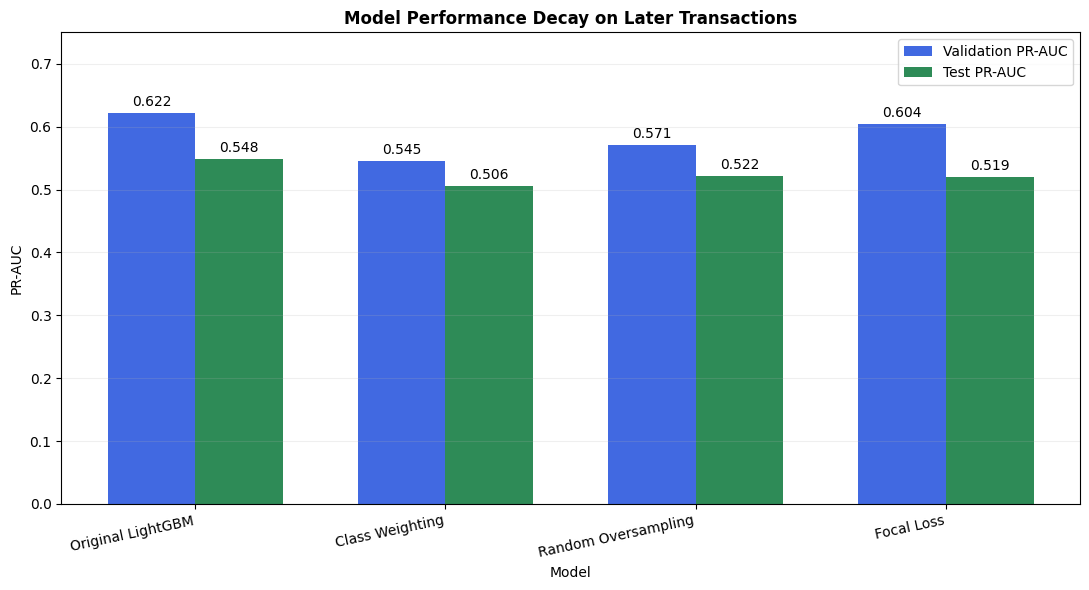


PERFORMANCE DECAY ANALYSIS COMPLETED


In [35]:
# Section 5.14.6: Compare validation and test PR-AUC

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Validation PR-AUC values from earlier experiments
validation_pr_auc = {
    "Original LightGBM": 0.6216,
    "Class Weighting": 0.5450,
    "Random Oversampling": 0.5707,
    "Focal Loss": 0.6041
}

decay_results = []

for model_name, val_score in validation_pr_auc.items():

    test_score = float(
        test_results_df.loc[
            test_results_df["Model"] == model_name,
            "PR-AUC"
        ].iloc[0]
    )

    absolute_drop = val_score - test_score
    relative_drop = (absolute_drop / val_score) * 100

    decay_results.append({
        "Model": model_name,
        "Validation PR-AUC": val_score,
        "Test PR-AUC": test_score,
        "Absolute Drop": absolute_drop,
        "Relative Drop (%)": relative_drop
    })

decay_df = pd.DataFrame(decay_results)

print("VALIDATION VS TEST PERFORMANCE DECAY")
print("-" * 55)
display(decay_df.round(4))

# Plot validation and test PR-AUC
x = np.arange(len(decay_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width / 2,
    decay_df["Validation PR-AUC"],
    width,
    label="Validation PR-AUC",
    color="royalblue"
)

bars2 = ax.bar(
    x + width / 2,
    decay_df["Test PR-AUC"],
    width,
    label="Test PR-AUC",
    color="seagreen"
)

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

ax.set_title(
    "Model Performance Decay on Later Transactions",
    fontweight="bold"
)

ax.set_ylabel("PR-AUC")
ax.set_xlabel("Model")
ax.set_xticks(x)
ax.set_xticklabels(decay_df["Model"], rotation=12, ha="right")
ax.set_ylim(0, 0.75)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nPERFORMANCE DECAY ANALYSIS COMPLETED")


### 5.14.7 The Precision at the Fixed Alert Budget on the Test Dataset

In [36]:
# Section 5.14.7: Evaluate precision at fixed alert budgets

import numpy as np
import pandas as pd

alert_budgets = [0.5, 1.0, 2.0, 5.0]

y_true = np.asarray(y_test).ravel().astype(int)
total_fraud = int(np.sum(y_true == 1))

budget_results = []

print("FINAL TEST - PRECISION AT FIXED ALERT BUDGET")
print("-" * 55)

for model_name, probabilities in test_probabilities.items():

    probabilities = np.asarray(probabilities).ravel()

    # Rank transactions from highest to lowest fraud score
    ranked_indices = np.argsort(-probabilities, kind="stable")

    for budget in alert_budgets:

        number_of_alerts = max(
            1, int(np.ceil(len(y_true) * budget / 100))
        )

        selected_indices = ranked_indices[:number_of_alerts]

        fraud_detected = int(
            np.sum(y_true[selected_indices] == 1)
        )

        precision = fraud_detected / number_of_alerts
        recall = fraud_detected / total_fraud

        budget_results.append({
            "Model": model_name,
            "Alert Budget (%)": budget,
            "Number of Alerts": number_of_alerts,
            "Fraud Detected": fraud_detected,
            "Precision": precision,
            "Recall": recall
        })

test_budget_df = pd.DataFrame(budget_results)

display(
    test_budget_df.round({
        "Precision": 4,
        "Recall": 4
    })
)

print("\nBEST MODEL AT 1% ALERT BUDGET")
print("-" * 55)

one_percent = test_budget_df[
    test_budget_df["Alert Budget (%)"] == 1.0
]

best_at_one_percent = one_percent.loc[
    one_percent["Fraud Detected"].idxmax()
]

print("Model:", best_at_one_percent["Model"])
print("Fraud detected:", int(best_at_one_percent["Fraud Detected"]))
print("Precision:", round(best_at_one_percent["Precision"], 4))
print("Recall:", round(best_at_one_percent["Recall"], 4))

print("\nFIXED ALERT BUDGET EVALUATION COMPLETED")


FINAL TEST - PRECISION AT FIXED ALERT BUDGET
-------------------------------------------------------


,Model,Alert Budget (%),Number of Alerts,Fraud Detected,Precision,Recall
0,Original LightGBM,0.5,443,415,0.9368,0.1346
1,Original LightGBM,1.0,886,788,0.8894,0.2556
2,Original LightGBM,2.0,1772,1281,0.7229,0.4155
3,Original LightGBM,5.0,4430,1799,0.4061,0.5835
4,Class Weighting,0.5,443,407,0.9187,0.1320
5,Class Weighting,1.0,886,795,0.8973,0.2579
6,Class Weighting,2.0,1772,1203,0.6789,0.3902
7,Class Weighting,5.0,4430,1668,0.3765,0.5410
8,Random Oversampling,0.5,443,414,0.9345,0.1343
9,Random Oversampling,1.0,886,789,0.8905,0.2559



BEST MODEL AT 1% ALERT BUDGET
-------------------------------------------------------
Model: Class Weighting
Fraud detected: 795
Precision: 0.8973
Recall: 0.2579

FIXED ALERT BUDGET EVALUATION COMPLETED


### 5.14.8 Expected Monetary Cost on the Test Dataset

In [37]:
# Section 5.14.8: Expected Monetary Cost on the Test Dataset

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

false_negative_cost = 1000
false_positive_cost = 50
classification_threshold = 0.5

cost_results = []

print("FINAL TEST - EXPECTED MONETARY COST")
print("-" * 55)

for model_name, probabilities in test_probabilities.items():

    probabilities = np.asarray(probabilities).ravel()

    predictions = (
        probabilities >= classification_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    missed_fraud_cost = fn * false_negative_cost
    false_alert_cost = fp * false_positive_cost

    total_cost = missed_fraud_cost + false_alert_cost

    cost_results.append({
        "Model": model_name,
        "False Negatives": int(fn),
        "False Positives": int(fp),
        "Missed Fraud Cost (ZAR)": missed_fraud_cost,
        "False Alert Cost (ZAR)": false_alert_cost,
        "Total Expected Cost (ZAR)": total_cost,
        "Average Cost per Transaction (ZAR)": total_cost / len(y_test)
    })

test_cost_df = pd.DataFrame(cost_results)

display(test_cost_df.round(2))

best_cost_model = test_cost_df.loc[
    test_cost_df["Total Expected Cost (ZAR)"].idxmin()
]

print("\nLOWEST ESTIMATED COST")
print("-" * 55)
print("Model:", best_cost_model["Model"])
print(
    "Total estimated cost: R",
    f'{best_cost_model["Total Expected Cost (ZAR)"]:,.2f}'
)

print("\nEXPECTED MONETARY COST EVALUATION COMPLETED")


FINAL TEST - EXPECTED MONETARY COST
-------------------------------------------------------


,Model,False Negatives,False Positives,Missed Fraud Cost (ZAR),False Alert Cost (ZAR),Total Expected Cost (ZAR),Average Cost per Transaction (ZAR)
0,Original LightGBM,1990,218,1990000,10900,2000900,22.59
1,Class Weighting,1004,6859,1004000,342950,1346950,15.21
2,Random Oversampling,1584,1496,1584000,74800,1658800,18.73
3,Focal Loss,2007,269,2007000,13450,2020450,22.81



LOWEST ESTIMATED COST
-------------------------------------------------------
Model: Class Weighting
Total estimated cost: R 1,346,950.00

EXPECTED MONETARY COST EVALUATION COMPLETED


### 5.14.9 Save the final test Evaluation results

In [38]:
# Section 5.14.9: Save final test evaluation results

import os
from google.colab import files

os.makedirs("results", exist_ok=True)

# Save final model performance
test_results_df.to_csv(
    "results/final_test_performance.csv",
    index=False
)

# Save validation vs test performance decay
decay_df.to_csv(
    "results/validation_test_decay.csv",
    index=False
)

# Save precision at fixed alert budgets
test_budget_df.to_csv(
    "results/final_test_alert_budget.csv",
    index=False
)

# Save expected monetary costs
test_cost_df.to_csv(
    "results/final_test_monetary_cost.csv",
    index=False
)

print("FINAL TEST RESULTS SAVED SUCCESSFULLY")
print("-" * 50)

filenames = [
    "final_test_performance.csv",
    "validation_test_decay.csv",
    "final_test_alert_budget.csv",
    "final_test_monetary_cost.csv"
]

for filename in filenames:
    path = os.path.join("results", filename)
    print("Saved:", path)
    files.download(path)

print("\nALL FINAL TEST RESULT FILES DOWNLOADED")


FINAL TEST RESULTS SAVED SUCCESSFULLY
--------------------------------------------------
Saved: results/final_test_performance.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: results/validation_test_decay.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

Saved: results/final_test_monetary_cost.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL FINAL TEST RESULT FILES DOWNLOADED


### 5.15 Final Test Evaluation of the TabNet and the FT-Transformer

In [39]:
# Section 5.15.1: Check available deep learning variables

variables_to_check = [
    "X_test",
    "y_test",
    "tabnet_model",
    "ft_model",
    "device",
    "FTTransformer",
    "num_features",
    "cat_cardinalities",
    "X_test_num",
    "X_test_cat",
    "test_loader"
]

print("DEEP LEARNING TEST EVALUATION - VARIABLE CHECK")
print("-" * 55)

for variable_name in variables_to_check:
    if variable_name in globals():
        print(f"AVAILABLE: {variable_name}")
    else:
        print(f"NOT AVAILABLE: {variable_name}")

print("\nVARIABLE CHECK COMPLETED")

DEEP LEARNING TEST EVALUATION - VARIABLE CHECK
-------------------------------------------------------
AVAILABLE: X_test
AVAILABLE: y_test
NOT AVAILABLE: tabnet_model
NOT AVAILABLE: ft_model
AVAILABLE: device
AVAILABLE: FTTransformer
NOT AVAILABLE: num_features
NOT AVAILABLE: cat_cardinalities
NOT AVAILABLE: X_test_num
NOT AVAILABLE: X_test_cat
NOT AVAILABLE: test_loader

VARIABLE CHECK COMPLETED


### 5.15.2 Inspecting of the saved Deep Learning Models Files

In [42]:

# Section 5.15.2: Inspect saved deep learning models

import os
import zipfile
import torch

model_files = [
    "tabnet_trained_model.zip",
    "ft_transformer_trained_model.pth"
]

print("SAVED DEEP LEARNING MODEL INSPECTION")
print("-" * 55)

for filename in model_files:
    if os.path.exists(filename):
        print(f"FOUND: {filename}")
        print(
            "File size:",
            round(os.path.getsize(filename) / (1024 * 1024), 2),
            "MB"
        )
    else:
        print(f"NOT FOUND: {filename}")

# Inspect TabNet archive
tabnet_path = "tabnet_trained_model.zip"

if os.path.exists(tabnet_path):
    print("\nTABNET ARCHIVE CONTENTS")
    print("-" * 55)

    with zipfile.ZipFile(tabnet_path, "r") as archive:
        for filename in archive.namelist():
            print(filename)

# Inspect FT-Transformer checkpoint
ft_path = "ft_transformer_trained_model.pth"

if os.path.exists(ft_path):
    print("\nFT-TRANSFORMER CHECKPOINT CONTENTS")
    print("-" * 55)

    # Only load checkpoints created by you or another trusted source
    checkpoint = torch.load(
        ft_path,
        map_location="cpu",
        weights_only=False
    )

    print("Checkpoint keys:", list(checkpoint.keys()))

    if "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]

        print("Number of parameter tensors:", len(state_dict))

        print("\nFirst five parameter names:")

        for name in list(state_dict.keys())[:5]:
            print(name)

print("\nMODEL INSPECTION COMPLETED")


SAVED DEEP LEARNING MODEL INSPECTION
-------------------------------------------------------
FOUND: tabnet_trained_model.zip
File size: 0.27 MB
FOUND: ft_transformer_trained_model.pth
File size: 3.99 MB

TABNET ARCHIVE CONTENTS
-------------------------------------------------------
network.pt
model_params.json

FT-TRANSFORMER CHECKPOINT CONTENTS
-------------------------------------------------------
Checkpoint keys: ['model_state_dict', 'best_epoch', 'best_validation_pr_auc', 'training_time_seconds']
Number of parameter tensors: 53

First five parameter names:
cls_embedding.weight
cont_embeddings.weight
cont_embeddings.bias
backbone.blocks.0.attention.W_q.weight
backbone.blocks.0.attention.W_q.bias

MODEL INSPECTION COMPLETED


### 5.15.3 Load the Trained TabNet Model

In [43]:
# Section 5.15.3: Load the trained TabNet model

import os
from pytorch_tabnet.tab_model import TabNetClassifier

print("LOADING TRAINED TABNET MODEL")
print("-" * 55)

tabnet_path = "tabnet_trained_model.zip"

if not os.path.exists(tabnet_path):
    raise FileNotFoundError(
        "TabNet model file not found. Please upload it first."
    )

# Create TabNet classifier
tabnet_model = TabNetClassifier()

# Restore saved model configuration and trained weights
tabnet_model.load_model(tabnet_path)

print("\nTABNET MODEL LOADED SUCCESSFULLY")
print("-" * 55)
print("Model type:", type(tabnet_model).__name__)
print("Input features:", tabnet_model.input_dim)
print("Output classes:", tabnet_model.output_dim)

LOADING TRAINED TABNET MODEL
-------------------------------------------------------


/usr/local/lib/python3.13/dist-packages/pytorch_tabnet/abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")



TABNET MODEL LOADED SUCCESSFULLY
-------------------------------------------------------
Model type: TabNetClassifier
Input features: 389
Output classes: 2


### 5.15.4 Verify the TabNet Test Data Compatibility

In [44]:
# Section 5.15.4: Verify TabNet test data compatibility

import numpy as np

print("TABNET TEST DATA COMPATIBILITY CHECK")
print("-" * 55)

print("Test data shape:", X_test.shape)
print("Model expected features:", tabnet_model.input_dim)

if X_test.shape[1] != tabnet_model.input_dim:
    raise ValueError(
        "Feature count mismatch between test data and TabNet model."
    )

# Convert test data to NumPy format
if hasattr(X_test, "to_numpy"):
    X_test_tabnet = X_test.to_numpy(dtype=np.float32)
else:
    X_test_tabnet = np.asarray(X_test, dtype=np.float32)

print("Converted test data shape:", X_test_tabnet.shape)

# Check for invalid values
print("All values finite:", np.isfinite(X_test_tabnet).all())

if not np.isfinite(X_test_tabnet).all():
    raise ValueError(
        "Test data contains NaN or infinite values."
    )

print("\nTABNET TEST DATA COMPATIBILITY CHECK COMPLETED")

TABNET TEST DATA COMPATIBILITY CHECK
-------------------------------------------------------
Test data shape: (88581, 389)
Model expected features: 389
Converted test data shape: (88581, 389)
All values finite: True

TABNET TEST DATA COMPATIBILITY CHECK COMPLETED


### 5.15.5 Generate the TabNet Final Test Predictions

In [45]:
# Section 5.15.5: Generate TabNet final test predictions

import numpy as np
import time

print("GENERATING TABNET FINAL TEST PREDICTIONS")
print("-" * 55)

start_time = time.time()

# Generate fraud probabilities using the saved TabNet model
tabnet_test_probabilities = tabnet_model.predict_proba(
    X_test_tabnet
)[:, 1]

tabnet_prediction_time = time.time() - start_time

# Verify predictions
print("Predictions generated:", len(tabnet_test_probabilities))
print("Expected transactions:", len(y_test))

print(
    "Minimum fraud probability:",
    round(float(np.min(tabnet_test_probabilities)), 6)
)

print(
    "Maximum fraud probability:",
    round(float(np.max(tabnet_test_probabilities)), 6)
)

print(
    "Average fraud probability:",
    round(float(np.mean(tabnet_test_probabilities)), 6)
)

print(
    "All predictions finite:",
    bool(np.isfinite(tabnet_test_probabilities).all())
)

print(
    "Prediction time (seconds):",
    round(tabnet_prediction_time, 2)
)

# Check prediction count and probability range
assert len(tabnet_test_probabilities) == len(y_test), \
    "Prediction count does not match test labels."

assert np.isfinite(tabnet_test_probabilities).all(), \
    "Predictions contain invalid values."

assert np.all(
    (tabnet_test_probabilities >= 0) &
    (tabnet_test_probabilities <= 1)
), "Predictions are outside the probability range."

print("\nTABNET FINAL TEST PREDICTIONS COMPLETED")


GENERATING TABNET FINAL TEST PREDICTIONS
-------------------------------------------------------
Predictions generated: 88581
Expected transactions: 88581
Minimum fraud probability: 0.0
Maximum fraud probability: 1.0
Average fraud probability: 0.035012
All predictions finite: True
Prediction time (seconds): 2.37

TABNET FINAL TEST PREDICTIONS COMPLETED


### 5.15.6 TabNet Final Test Perfomance Evaluation

In [46]:
# Section 5.15.6: TabNet final test performance evaluation

import numpy as np
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    confusion_matrix
)
from sklearn.calibration import calibration_curve

print("TABNET FINAL TEST PERFORMANCE EVALUATION")
print("-" * 55)

# Convert labels to a NumPy array
y_test_array = np.asarray(y_test).ravel()

# Convert probabilities into binary predictions
# Threshold of 0.5: probability >= 0.5 means fraud
tabnet_test_predictions = (
    tabnet_test_probabilities >= 0.5
).astype(int)

# Calculate performance metrics
tabnet_test_pr_auc = average_precision_score(
    y_test_array, tabnet_test_probabilities
)

tabnet_test_roc_auc = roc_auc_score(
    y_test_array, tabnet_test_probabilities
)

tabnet_test_precision = precision_score(
    y_test_array, tabnet_test_predictions,
    zero_division=0
)

tabnet_test_recall = recall_score(
    y_test_array, tabnet_test_predictions,
    zero_division=0
)

tabnet_test_f1 = f1_score(
    y_test_array, tabnet_test_predictions,
    zero_division=0
)

tabnet_test_brier = brier_score_loss(
    y_test_array, tabnet_test_probabilities
)

tabnet_test_cm = confusion_matrix(
    y_test_array, tabnet_test_predictions
)

# Expected Calibration Error (10 equal-width bins)
def calculate_tabnet_ece(y_true, probabilities, n_bins=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_indices = np.minimum(
        np.digitize(probabilities, bin_edges[1:-1]),
        n_bins - 1
    )

    ece = 0.0

    for bin_id in range(n_bins):
        mask = bin_indices == bin_id

        if np.any(mask):
            bin_accuracy = np.mean(y_true[mask])
            bin_confidence = np.mean(probabilities[mask])

            ece += np.mean(mask) * abs(
                bin_accuracy - bin_confidence
            )

    return float(ece)

tabnet_test_ece = calculate_tabnet_ece(
    y_test_array, tabnet_test_probabilities
)

# Display results
print(f"PR-AUC: {tabnet_test_pr_auc:.4f}")
print(f"ROC-AUC: {tabnet_test_roc_auc:.4f}")
print(f"Precision: {tabnet_test_precision:.4f}")
print(f"Recall: {tabnet_test_recall:.4f}")
print(f"F1-score: {tabnet_test_f1:.4f}")
print(f"Brier Score: {tabnet_test_brier:.4f}")
print(f"Expected Calibration Error: {tabnet_test_ece:.4f}")

print("\nCONFUSION MATRIX")
print("-" * 55)
print(tabnet_test_cm)

print("\nTABNET FINAL TEST EVALUATION COMPLETED")


TABNET FINAL TEST PERFORMANCE EVALUATION
-------------------------------------------------------
PR-AUC: 0.4082
ROC-AUC: 0.8473
Precision: 0.6557
Recall: 0.3163
F1-score: 0.4267
Brier Score: 0.0259
Expected Calibration Error: 0.0078

CONFUSION MATRIX
-------------------------------------------------------
[[84986   512]
 [ 2108   975]]

TABNET FINAL TEST EVALUATION COMPLETED


### 5.15.7 TabNet Validation to test of the performance Decay

In [47]:
# Section 5.15.7: TabNet validation-to-test performance decay

print("TABNET VALIDATION VS TEST PERFORMANCE DECAY")
print("-" * 55)

tabnet_validation_pr_auc = 0.4517
tabnet_final_test_pr_auc = tabnet_test_pr_auc

absolute_drop = (
    tabnet_validation_pr_auc - tabnet_final_test_pr_auc
)

relative_drop = (
    absolute_drop / tabnet_validation_pr_auc
) * 100

print(f"Validation PR-AUC: {tabnet_validation_pr_auc:.4f}")
print(f"Test PR-AUC: {tabnet_final_test_pr_auc:.4f}")
print(f"Absolute drop: {absolute_drop:.4f}")
print(f"Relative drop: {relative_drop:.2f}%")

print("\nTABNET PERFORMANCE DECAY ANALYSIS COMPLETED")


TABNET VALIDATION VS TEST PERFORMANCE DECAY
-------------------------------------------------------
Validation PR-AUC: 0.4517
Test PR-AUC: 0.4082
Absolute drop: 0.0435
Relative drop: 9.63%

TABNET PERFORMANCE DECAY ANALYSIS COMPLETED


### 5.15.8 Restore the Trained FT-Transformer Model

In [48]:
# Section 5.15.8: Restore the trained FT-Transformer model

import os
import torch
from rtdl_revisiting_models import FTTransformer

print("RESTORING TRAINED FT-TRANSFORMER MODEL")
print("-" * 55)

# Select the available processing device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Set the same seed used in Notebook 04
torch.manual_seed(42)

# Recreate the exact model architecture from Notebook 04
ft_model = FTTransformer(
    n_cont_features=389,
    cat_cardinalities=[],
    d_out=1,
    **FTTransformer.get_default_kwargs()
).to(device)

# Locate the saved checkpoint
ft_path = "ft_transformer_trained_model.pth"

if not os.path.exists(ft_path):
    raise FileNotFoundError(
        "FT-Transformer checkpoint not found."
    )

# Load only your own trusted checkpoint
checkpoint = torch.load(
    ft_path,
    map_location=device,
    weights_only=False
)

# Restore trained model parameters
ft_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

# Switch to evaluation mode
ft_model.eval()

print("FT-TRANSFORMER RESTORED SUCCESSFULLY")
print("-" * 55)
print("Device:", device)
print("Numerical features:", 389)
print("Output dimension:", 1)
print("Best training epoch:", checkpoint.get("best_epoch"))
print(
    "Best validation PR-AUC:",
    checkpoint.get("best_validation_pr_auc")
)

print("\nFT-TRANSFORMER MODEL READY FOR TEST EVALUATION")


RESTORING TRAINED FT-TRANSFORMER MODEL
-------------------------------------------------------
FT-TRANSFORMER RESTORED SUCCESSFULLY
-------------------------------------------------------
Device: cuda
Numerical features: 389
Output dimension: 1
Best training epoch: 12
Best validation PR-AUC: 0.4504804672109288

FT-TRANSFORMER MODEL READY FOR TEST EVALUATION


### 5.15.9  Prepare the Ft-Transformer Test Data

In [49]:
# Section 5.15.9: Inspect FT-Transformer test preprocessing

import numpy as np
import torch

print("FT-TRANSFORMER TEST PREPROCESSING CHECK")
print("-" * 55)

print("Original test shape:", X_test.shape)
print("Expected model features:", 389)

# Check variables from Notebook 04
variables_to_check = [
    "X_train_np",
    "X_val_np",
    "X_test_np",
    "X_test_num",
    "test_loader",
    "scaler",
    "standard_scaler"
]

for name in variables_to_check:
    if name in globals():
        value = globals()[name]
        print(f"AVAILABLE: {name}")
        if hasattr(value, "shape"):
            print("  Shape:", value.shape)
    else:
        print(f"NOT AVAILABLE: {name}")

# Check test feature values
X_test_check = np.asarray(X_test, dtype=np.float32)

print("\nTEST FEATURE STATISTICS")
print("-" * 55)
print("Minimum value:", float(np.min(X_test_check)))
print("Maximum value:", float(np.max(X_test_check)))
print("Mean value:", float(np.mean(X_test_check)))
print("All values finite:", bool(np.isfinite(X_test_check).all()))

print("\nFT-TRANSFORMER PREPROCESSING CHECK COMPLETED")


FT-TRANSFORMER TEST PREPROCESSING CHECK
-------------------------------------------------------
Original test shape: (88581, 389)
Expected model features: 389
NOT AVAILABLE: X_train_np
NOT AVAILABLE: X_val_np
NOT AVAILABLE: X_test_np
NOT AVAILABLE: X_test_num
NOT AVAILABLE: test_loader
NOT AVAILABLE: scaler
NOT AVAILABLE: standard_scaler

TEST FEATURE STATISTICS
-------------------------------------------------------
Minimum value: 0.0
Maximum value: 161644.296875
Mean value: 89.6004638671875
All values finite: True

FT-TRANSFORMER PREPROCESSING CHECK COMPLETED


### 5.15.10 Generate the FT-Transformer Final Test Predictions

In [50]:
# Section 5.15.10: Generate FT-Transformer final test predictions

import numpy as np
import torch
import time

print("GENERATING FT-TRANSFORMER FINAL TEST PREDICTIONS")
print("-" * 55)

# Prepare test features using the same conversion as Notebook 04
X_test_np = X_test.to_numpy(dtype=np.float32)

# Verify dimensions and values
assert X_test_np.shape[1] == 389, "Incorrect number of features."
assert np.isfinite(X_test_np).all(), "Invalid test feature values."

# Set model to evaluation mode
ft_model.eval()

batch_size = 1024
prediction_batches = []

start_time = time.time()

# Disable gradient calculations during prediction
with torch.no_grad():

    for start in range(0, len(X_test_np), batch_size):

        end = start + batch_size

        X_batch = torch.tensor(
            X_test_np[start:end],
            dtype=torch.float32,
            device=device
        )

        # FT-Transformer requires numerical and categorical inputs
        # There are no categorical features in this project
        logits = ft_model(X_batch, None)

        # Convert logits to fraud probabilities
        probabilities = torch.sigmoid(
            logits.reshape(-1)
        )

        prediction_batches.append(
            probabilities.cpu().numpy()
        )

# Combine all prediction batches
ft_test_probabilities = np.concatenate(
    prediction_batches
)

ft_prediction_time = time.time() - start_time

print("Predictions generated:", len(ft_test_probabilities))
print("Expected transactions:", len(y_test))

print(
    "Minimum fraud probability:",
    round(float(np.min(ft_test_probabilities)), 6)
)

print(
    "Maximum fraud probability:",
    round(float(np.max(ft_test_probabilities)), 6)
)

print(
    "Average fraud probability:",
    round(float(np.mean(ft_test_probabilities)), 6)
)

print(
    "All predictions finite:",
    bool(np.isfinite(ft_test_probabilities).all())
)

print(
    "Prediction time (seconds):",
    round(ft_prediction_time, 2)
)

# Validate prediction output
assert len(ft_test_probabilities) == len(y_test), \
    "Prediction count does not match test labels."

assert np.isfinite(ft_test_probabilities).all(), \
    "Predictions contain invalid values."

assert np.all(
    (ft_test_probabilities >= 0) &
    (ft_test_probabilities <= 1)
), "Predictions are outside the probability range."

print("\nFT-TRANSFORMER FINAL TEST PREDICTIONS COMPLETED")


GENERATING FT-TRANSFORMER FINAL TEST PREDICTIONS
-------------------------------------------------------
Predictions generated: 88581
Expected transactions: 88581
Minimum fraud probability: 0.001489
Maximum fraud probability: 0.994575
Average fraud probability: 0.03704
All predictions finite: True
Prediction time (seconds): 46.98

FT-TRANSFORMER FINAL TEST PREDICTIONS COMPLETED


### 5.15.11 FT-Transformer Final test Perfomace Evaluation

In [51]:

# Section 5.15.11: FT-Transformer final test evaluation

import numpy as np
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    confusion_matrix
)

print("FT-TRANSFORMER FINAL TEST PERFORMANCE EVALUATION")
print("-" * 55)

y_test_array = np.asarray(y_test).ravel()

# Apply the same 0.5 classification threshold
ft_test_predictions = (
    ft_test_probabilities >= 0.5
).astype(int)

# Calculate performance metrics
ft_test_pr_auc = average_precision_score(
    y_test_array, ft_test_probabilities
)

ft_test_roc_auc = roc_auc_score(
    y_test_array, ft_test_probabilities
)

ft_test_precision = precision_score(
    y_test_array, ft_test_predictions,
    zero_division=0
)

ft_test_recall = recall_score(
    y_test_array, ft_test_predictions,
    zero_division=0
)

ft_test_f1 = f1_score(
    y_test_array, ft_test_predictions,
    zero_division=0
)

ft_test_brier = brier_score_loss(
    y_test_array, ft_test_probabilities
)

ft_test_cm = confusion_matrix(
    y_test_array, ft_test_predictions
)

# Calculate ECE using the same 10-bin method as TabNet
ft_test_ece = calculate_tabnet_ece(
    y_test_array, ft_test_probabilities,
    n_bins=10
)

# Display results
print(f"PR-AUC: {ft_test_pr_auc:.4f}")
print(f"ROC-AUC: {ft_test_roc_auc:.4f}")
print(f"Precision: {ft_test_precision:.4f}")
print(f"Recall: {ft_test_recall:.4f}")
print(f"F1-score: {ft_test_f1:.4f}")
print(f"Brier Score: {ft_test_brier:.4f}")
print(f"Expected Calibration Error: {ft_test_ece:.4f}")

print("\nCONFUSION MATRIX")
print("-" * 55)
print(ft_test_cm)

print("\nFT-TRANSFORMER FINAL TEST EVALUATION COMPLETED")


FT-TRANSFORMER FINAL TEST PERFORMANCE EVALUATION
-------------------------------------------------------
PR-AUC: 0.4414
ROC-AUC: 0.8554
Precision: 0.6244
Recall: 0.3597
F1-score: 0.4565
Brier Score: 0.0261
Expected Calibration Error: 0.0117

CONFUSION MATRIX
-------------------------------------------------------
[[84831   667]
 [ 1974  1109]]

FT-TRANSFORMER FINAL TEST EVALUATION COMPLETED


### 5.15.12 FT-Transformer Validation to Test the Performance Decay

In [52]:
# Section 5.15.12: FT-Transformer performance decay

print("FT-TRANSFORMER VALIDATION VS TEST PERFORMANCE DECAY")
print("-" * 55)

# Use the full-precision validation score from the saved checkpoint
ft_validation_pr_auc = float(
    checkpoint["best_validation_pr_auc"]
)

ft_final_test_pr_auc = float(ft_test_pr_auc)

absolute_drop = ft_validation_pr_auc - ft_final_test_pr_auc

relative_drop = (
    absolute_drop / ft_validation_pr_auc
) * 100

print(f"Validation PR-AUC: {ft_validation_pr_auc:.4f}")
print(f"Test PR-AUC: {ft_final_test_pr_auc:.4f}")
print(f"Absolute drop: {absolute_drop:.4f}")
print(f"Relative drop: {relative_drop:.2f}%")

print("\nFT-TRANSFORMER PERFORMANCE DECAY ANALYSIS COMPLETED")


FT-TRANSFORMER VALIDATION VS TEST PERFORMANCE DECAY
-------------------------------------------------------
Validation PR-AUC: 0.4505
Test PR-AUC: 0.4414
Absolute drop: 0.0091
Relative drop: 2.02%

FT-TRANSFORMER PERFORMANCE DECAY ANALYSIS COMPLETED


### 5.15.13 Final Deep Learning Model Comparison

In [53]:
# Section 5.15.13: Final comparison of main models

import pandas as pd

final_model_comparison_df = pd.DataFrame([
    {
        "Model": "LightGBM",
        "PR-AUC": 0.5480,
        "ROC-AUC": 0.9023,
        "Precision": 0.8337,
        "Recall": 0.3545,
        "F1-Score": 0.4975,
        "Brier Score": 0.0218,
        "ECE": 0.0083,
        "PR-AUC Decay (%)": 11.84
    },
    {
        "Model": "TabNet",
        "PR-AUC": tabnet_test_pr_auc,
        "ROC-AUC": tabnet_test_roc_auc,
        "Precision": tabnet_test_precision,
        "Recall": tabnet_test_recall,
        "F1-Score": tabnet_test_f1,
        "Brier Score": tabnet_test_brier,
        "ECE": tabnet_test_ece,
        "PR-AUC Decay (%)": 9.63
    },
    {
        "Model": "FT-Transformer",
        "PR-AUC": ft_test_pr_auc,
        "ROC-AUC": ft_test_roc_auc,
        "Precision": ft_test_precision,
        "Recall": ft_test_recall,
        "F1-Score": ft_test_f1,
        "Brier Score": ft_test_brier,
        "ECE": ft_test_ece,
        "PR-AUC Decay (%)": relative_drop
    }
])

print("FINAL MODEL COMPARISON")
print("-" * 55)

display(final_model_comparison_df.round(4))

best_model = final_model_comparison_df.loc[
    final_model_comparison_df["PR-AUC"].idxmax()
]

print("\nBEST MODEL BASED ON FINAL TEST PR-AUC")
print("-" * 55)
print("Model:", best_model["Model"])
print("PR-AUC:", round(best_model["PR-AUC"], 4))

print("\nFINAL MODEL COMPARISON COMPLETED")


FINAL MODEL COMPARISON
-------------------------------------------------------


,Model,PR-AUC,ROC-AUC,Precision,Recall,F1-Score,Brier Score,ECE,PR-AUC Decay (%)
0,LightGBM,0.5480,0.9023,0.8337,0.3545,0.4975,0.0218,0.0083,11.8400
1,TabNet,0.4082,0.8473,0.6557,0.3163,0.4267,0.0259,0.0078,9.6300
2,FT-Transformer,0.4414,0.8554,0.6244,0.3597,0.4565,0.0261,0.0117,2.0164



BEST MODEL BASED ON FINAL TEST PR-AUC
-------------------------------------------------------
Model: LightGBM
PR-AUC: 0.548

FINAL MODEL COMPARISON COMPLETED


### 5.15.14 The Final Model Comparison at fixed Alert Budgets

In [55]:
# Section 5.15.14: Final Model Comparison at Fixed Alert Budgets

import os
import joblib
import numpy as np
import pandas as pd

print("FINAL MODEL COMPARISON AT FIXED ALERT BUDGETS")
print("-" * 55)

# --------------------------------------------------
# 1. Load the original trained LightGBM model
# --------------------------------------------------

possible_paths = [
    "lightgbm_tuned_model.joblib",
    "results/lightgbm_tuned_model.joblib"
]

model_path = next(
    (path for path in possible_paths if os.path.isfile(path)),
    None
)

if model_path is None:
    raise FileNotFoundError(
        "Cannot find lightgbm_tuned_model.joblib. "
        "Please upload the saved model before continuing."
    )

original_lgbm_model = joblib.load(model_path)

print("SUCCESS: Original LightGBM model loaded")
print("Model file:", model_path)

# --------------------------------------------------
# 2. Generate LightGBM test probabilities
# --------------------------------------------------

lgbm_test_probabilities = (
    original_lgbm_model.predict_proba(X_test)[:, 1]
)

print(
    "LightGBM predictions generated:",
    len(lgbm_test_probabilities)
)

# --------------------------------------------------
# 3. Check the deep learning predictions
# --------------------------------------------------

if "tabnet_test_probabilities" not in globals():
    raise NameError(
        "TabNet test predictions are missing. "
        "Run the earlier TabNet prediction cell."
    )

if "ft_test_probabilities" not in globals():
    raise NameError(
        "FT-Transformer test predictions are missing. "
        "Run Section 5.15.10 first."
    )

model_probabilities = {
    "LightGBM": lgbm_test_probabilities,
    "TabNet": tabnet_test_probabilities,
    "FT-Transformer": ft_test_probabilities
}

# --------------------------------------------------
# 4. Prepare test labels
# --------------------------------------------------

y_true = np.asarray(y_test).ravel()

assert set(np.unique(y_true)).issubset({0, 1}), (
    "Test labels must contain only 0 and 1."
)

total_transactions = len(y_true)
total_fraud = int(y_true.sum())

print("\nTEST DATA SUMMARY")
print("-" * 55)
print("Total transactions:", total_transactions)
print("Total fraud cases:", total_fraud)

# --------------------------------------------------
# 5. Validate prediction probabilities
# --------------------------------------------------

for model_name, probabilities in model_probabilities.items():

    probabilities = np.asarray(probabilities).ravel()

    assert len(probabilities) == total_transactions, (
        f"{model_name}: Incorrect prediction count."
    )

    assert np.isfinite(probabilities).all(), (
        f"{model_name}: Predictions contain invalid values."
    )

    assert np.all(
        (probabilities >= 0) & (probabilities <= 1)
    ), (
        f"{model_name}: Predictions must be between 0 and 1."
    )

    model_probabilities[model_name] = probabilities

print("\nAll model predictions verified successfully!")

# --------------------------------------------------
# 6. Calculate fixed alert budget performance
# --------------------------------------------------

alert_budgets = [0.5, 1.0, 2.0, 5.0]

results = []

for model_name, probabilities in model_probabilities.items():

    # Rank transactions by predicted fraud probability
    ranked_indices = np.argsort(-probabilities)

    for budget in alert_budgets:

        number_of_alerts = max(
            1,
            int(round(total_transactions * budget / 100))
        )

        selected_indices = ranked_indices[:number_of_alerts]

        fraud_detected = int(
            y_true[selected_indices].sum()
        )

        precision = fraud_detected / number_of_alerts

        recall = (
            fraud_detected / total_fraud
            if total_fraud > 0 else 0
        )

        results.append({
            "Model": model_name,
            "Alert Budget (%)": budget,
            "Number of Alerts": number_of_alerts,
            "Fraud Detected": fraud_detected,
            "Precision": precision,
            "Recall": recall
        })

# --------------------------------------------------
# 7. Display comparison table
# --------------------------------------------------

final_all_models_alert_budget_df = pd.DataFrame(results)

print("\nFINAL ALERT BUDGET COMPARISON")
print("-" * 55)

display(
    final_all_models_alert_budget_df.round(4)
)

# --------------------------------------------------
# 8. Identify best model at 1% alert budget
# --------------------------------------------------

one_percent_results = final_all_models_alert_budget_df[
    final_all_models_alert_budget_df["Alert Budget (%)"] == 1.0
]

best_index = one_percent_results[
    "Fraud Detected"
].idxmax()

best_model = one_percent_results.loc[best_index]

print("\nBEST MODEL AT 1% ALERT BUDGET")
print("-" * 55)

print("Model:", best_model["Model"])
print(
    "Number of alerts:",
    int(best_model["Number of Alerts"])
)
print(
    "Fraud detected:",
    int(best_model["Fraud Detected"])
)
print(
    "Precision:",
    round(best_model["Precision"], 4)
)
print(
    "Recall:",
    round(best_model["Recall"], 4)
)

print("\nFIXED ALERT BUDGET COMPARISON COMPLETED")


FINAL MODEL COMPARISON AT FIXED ALERT BUDGETS
-------------------------------------------------------
SUCCESS: Original LightGBM model loaded
Model file: lightgbm_tuned_model.joblib
LightGBM predictions generated: 88581

TEST DATA SUMMARY
-------------------------------------------------------
Total transactions: 88581
Total fraud cases: 3083

All model predictions verified successfully!

FINAL ALERT BUDGET COMPARISON
-------------------------------------------------------


,Model,Alert Budget (%),Number of Alerts,Fraud Detected,Precision,Recall
0,LightGBM,0.5,443,415,0.9368,0.1346
1,LightGBM,1.0,886,788,0.8894,0.2556
2,LightGBM,2.0,1772,1281,0.7229,0.4155
3,LightGBM,5.0,4429,1799,0.4062,0.5835
4,TabNet,0.5,443,363,0.8194,0.1177
5,TabNet,1.0,886,673,0.7596,0.2183
6,TabNet,2.0,1772,1087,0.6134,0.3526
7,TabNet,5.0,4429,1505,0.3398,0.4882
8,FT-Transformer,0.5,443,406,0.9165,0.1317
9,FT-Transformer,1.0,886,716,0.8081,0.2322



BEST MODEL AT 1% ALERT BUDGET
-------------------------------------------------------
Model: LightGBM
Number of alerts: 886
Fraud detected: 788
Precision: 0.8894
Recall: 0.2556

FIXED ALERT BUDGET COMPARISON COMPLETED


### 5.15.15 Final Monetary Cost Comparision

In [56]:
# Section 5.15.15: Final Monetary Cost Comparison

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

print("FINAL MODEL MONETARY COST COMPARISON")
print("-" * 55)

# Cost assumptions in South African Rand
false_negative_cost = 1000
false_positive_cost = 50
classification_threshold = 0.5

# Use the predictions verified in Section 5.15.14
required_models = [
    "LightGBM",
    "TabNet",
    "FT-Transformer"
]

assert "model_probabilities" in globals(), (
    "Run Section 5.15.14 before this cell."
)

y_true = np.asarray(y_test).ravel()
cost_results = []

for model_name in required_models:

    probabilities = np.asarray(
        model_probabilities[model_name]
    ).ravel()

    assert len(probabilities) == len(y_true), (
        f"Prediction count mismatch for {model_name}"
    )

    predictions = (
        probabilities >= classification_threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    missed_fraud_cost = int(fn) * false_negative_cost
    false_alert_cost = int(fp) * false_positive_cost

    total_cost = missed_fraud_cost + false_alert_cost
    average_cost = total_cost / len(y_true)

    cost_results.append({
        "Model": model_name,
        "False Negatives": int(fn),
        "False Positives": int(fp),
        "Missed Fraud Cost (ZAR)": missed_fraud_cost,
        "False Alert Cost (ZAR)": false_alert_cost,
        "Total Expected Cost (ZAR)": total_cost,
        "Average Cost per Transaction (ZAR)": average_cost
    })

final_all_models_cost_df = pd.DataFrame(cost_results)

print("\nMONETARY COST COMPARISON")
print("-" * 55)

display(final_all_models_cost_df.round(2))

best_cost_index = final_all_models_cost_df[
    "Total Expected Cost (ZAR)"
].idxmin()

best_cost_model = final_all_models_cost_df.loc[
    best_cost_index
]

print("\nLOWEST ESTIMATED MONETARY COST")
print("-" * 55)
print("Model:", best_cost_model["Model"])
print(
    "Total estimated cost: R {:,.2f}".format(
        best_cost_model["Total Expected Cost (ZAR)"]
    )
)

print("\nMONETARY COST COMPARISON COMPLETED")


FINAL MODEL MONETARY COST COMPARISON
-------------------------------------------------------

MONETARY COST COMPARISON
-------------------------------------------------------


,Model,False Negatives,False Positives,Missed Fraud Cost (ZAR),False Alert Cost (ZAR),Total Expected Cost (ZAR),Average Cost per Transaction (ZAR)
0,LightGBM,1990,218,1990000,10900,2000900,22.59
1,TabNet,2108,512,2108000,25600,2133600,24.09
2,FT-Transformer,1974,667,1974000,33350,2007350,22.66



LOWEST ESTIMATED MONETARY COST
-------------------------------------------------------
Model: LightGBM
Total estimated cost: R 2,000,900.00

MONETARY COST COMPARISON COMPLETED


### 5.16 Save the Fina Model Comparison Results

In [57]:
# Section 5.16: Save final model comparison results

import os
from google.colab import files

os.makedirs("results", exist_ok=True)

final_files = {
    "final_model_comparison.csv":
        final_model_comparison_df,

    "final_all_models_alert_budget.csv":
        final_all_models_alert_budget_df,

    "final_all_models_monetary_cost.csv":
        final_all_models_cost_df
}

print("SAVING FINAL MODEL COMPARISON RESULTS")
print("-" * 55)

for filename, dataframe in final_files.items():

    file_path = os.path.join("results", filename)

    dataframe.to_csv(file_path, index=False)

    print("SAVED:", file_path)

print("\nDOWNLOADING FINAL RESULTS")
print("-" * 55)

for filename in final_files:

    file_path = os.path.join("results", filename)

    files.download(file_path)

print("\nALL FINAL COMPARISON RESULTS SAVED SUCCESSFULLY")


SAVING FINAL MODEL COMPARISON RESULTS
-------------------------------------------------------
SAVED: results/final_model_comparison.csv
SAVED: results/final_all_models_alert_budget.csv
SAVED: results/final_all_models_monetary_cost.csv

DOWNLOADING FINAL RESULTS
-------------------------------------------------------


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


ALL FINAL COMPARISON RESULTS SAVED SUCCESSFULLY


###**5.17 Final Findings and Conclusion**

The focus of this project was to explore deep learning models for detecting fraudulent transactions using the IEEE-CIS Fraud Detection dataset. The study analyzed LightGBM, TabNet and FT-Transformer models through a chronologically organized validation and testing set. In addition, the research explored various methods for addressing class imbalances in the data, such as class weighting, random oversampling and focal loss.

### Research Question 1: Model Performance
LightGBM had the highest final test PR-AUC value of 0.5480. In the comparison, FT-Transformer had the final test PR-AUC value of the 0.4414 and the TabNet had the final test PR-AUC value of 0.4082. This means that the overall, LightGBM was able to identify fraudulent transactions more effectively compare to both FT-Transformer and TabNet. When applying an alert budget of 1%, LightGBM identified 788 fraudulent transactions. In comparison, FT-Transformer identified 716 fraudulent transactions and TabNet identified 673 fraudulent transactions.

###Research Question 2: Class Imbalance Strategies
The experiments conducted indicated that different class imbalance techniques had an impact on both model performance and calibration. Out of all the LightGBM models used in this study, the original LightGBM model produced the highest validation PR-AUC value of 0.6216. Class weighting increased the recall value to 0.7045; however, class weighting also decreased the precision value and the calibration quality. Random oversampling produced the highest validation F1-score value of 0.5413 out of the four LightGBM strategies. The experimental results demonstrate a trade-off between identifying more fraudulent activities and producing false positives.

###Research Question 3: Performance on Later Transactions
The PR-AUC of all three major models was lower for the later test dataset. The LightGBM dropped from 0.6216 to 0.5480, TabNet dropped from 0.4517 to 0.4082, and FT-Transformer dropped from 0.4505 to 0.4414. While LightGBM continued to be the best performing model on the later test dataset, FT-Transformer showed the least decrease in relative performance (approximately 2.02 percent).

###Monetary Cost Evaluation
Among the three top models evaluated using a cost of R1,000 for each missed fraud case and R50 for each false positive case, the lowest estimated cost was R2,000,900 with LightGBM when using a classification threshold of 0.5. On the other hand, the LightGBM experiment which utilized class weights produced an even lower estimated cost of R1,346,950, showing that the most effective model is dependent upon what the user wants to evaluate and how much they are willing to pay for errors.

###Limitations
The study only examined a single dataset, and the results may not apply to different fraud detection settings. The cost was used as an experimental variable and not obtained from a real-world financial organization. Also, the findings are dependent on the specific preprocessing techniques, classification thresholds, and training configurations chosen. To determine if the findings are robust, additional random seed experiments would need to be conducted.

###Conclusion
The results indicate that a well-tuned gradient boosted tree (LightGBM) model is still a viable baseline for fraud detection on this data set. While the deep learning models used in this study did not provide superior performance to LightGBM based on PR-AUC, FT-Transformer had less of a decline in performance over time compared to LightGBM. This research has demonstrated that methods for addressing class imbalance can improve the recall of fraud cases or lower the estimated costs associated with fraud; however, there is a trade-off. Improvements in recall or cost reduction can lead to an increase in false alarms and/or poorer calibration.
